# Mantenimiento predictivo en manufactura — AI4I 2020

**Curso:** Data Analytics en Gestión Industrial · **Proyecto:** Gestión Industrial con Datos Abiertos

## Fase 1 — Contexto y selección del dataset

**Sector:** manufactura (mecanizado / máquinas-herramienta).

**Problema industrial:** las fallas de máquina no planificadas detienen la línea, generan piezas defectuosas y costos de reparación correctiva. El objetivo es **anticipar la falla de la máquina** (`Machine failure`) a partir de variables de operación que ya se miden en planta (temperaturas, velocidad, torque y desgaste de herramienta), para pasar de un mantenimiento correctivo a uno **predictivo**.

### Ficha técnica del dataset

| Campo | Detalle |
|---|---|
| Nombre | AI4I 2020 Predictive Maintenance Dataset |
| Origen | UCI Machine Learning Repository (id 601) — listado en *awesome-industrial-datasets* |
| Autor | Stephan Matzka, HTW Berlin (2020) |
| Enlace | https://archive.ics.uci.edu/dataset/601/ai4i+2020+predictive+maintenance+dataset |
| Formato | CSV (1 archivo) |
| Tamaño | 10 000 filas × 14 columnas, ~510 KB |
| Variables | 1 id, 1 código de producto, 1 categórica (`Type`), 5 numéricas de proceso, 1 objetivo binaria y 5 modos de falla |
| Última actualización | Publicado en UCI el 29-08-2020 (versión única, sin actualizaciones) |
| Licencia | Creative Commons Attribution 4.0 (CC BY 4.0) |
| Nota | El dataset es **sintético**: lo generó el autor para reflejar datos reales de mantenimiento predictivo. Se declara aquí según la política de integridad del curso. |

### Valor del dato abierto para la toma de decisiones

* Permite construir y validar un modelo de mantenimiento predictivo **sin exponer datos propietarios** de la planta, y luego replicar el pipeline con datos internos.
* Las variables son las que entrega cualquier PLC/SCADA estándar, así que los hallazgos se pueden trasladar a la operación real.
* Al ser público y con licencia CC BY 4.0, el análisis es **reproducible y auditable** por terceros (proveedores, auditoría, academia).

### Reproducibilidad y uso de IA

* Semilla fija: `RANDOM_STATE = 42` en todos los splits, búsquedas y modelos.
* Entorno: ver la celda siguiente y el archivo `requirements.txt` del repositorio.
* **Declaración de uso de IA:** se usó un asistente de IA (Claude) como apoyo para revisar el notebook frente a los requerimientos y proponer celdas de EDA, tratamiento de outliers, KPIs y métricas. El equipo revisó y debe poder explicar cada línea y decisión.

In [1]:
import sys, platform
import numpy, pandas, sklearn, matplotlib, seaborn
print("Python      :", sys.version.split()[0], "|", platform.system())
for lib in (numpy, pandas, sklearn, matplotlib, seaborn):
    print(f"{lib.__name__:<12}:", lib.__version__)

Python      : 3.12.10 | Windows
numpy       : 2.5.5
pandas      : 3.1.1
sklearn     : 1.9.1
matplotlib  : 3.11.2
seaborn     : 0.13.2


## Fase 2 — ETL (ingeniería de datos)

**Ingesta:** lectura del CSV original de UCI (el separador se detecta automáticamente).

In [2]:
import pandas as pd

# Capa RAW: CSV original de UCI. sep=None detecta el separador (',' en el original, ';' si se guardó desde Excel)
df = pd.read_csv("../datasets/ai4i2020.csv", sep=None, engine="python", encoding="utf-8-sig")
df

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,9996,M24855,M,298.8,308.4,1604,29.5,14,0,0,0,0,0,0
9996,9997,H39410,H,298.9,308.4,1632,31.8,17,0,0,0,0,0,0
9997,9998,M24857,M,299.0,308.6,1645,33.4,22,0,0,0,0,0,0
9998,9999,H39412,H,299.0,308.7,1408,48.5,25,0,0,0,0,0,0


In [3]:
df

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,9996,M24855,M,298.8,308.4,1604,29.5,14,0,0,0,0,0,0
9996,9997,H39410,H,298.9,308.4,1632,31.8,17,0,0,0,0,0,0
9997,9998,M24857,M,299.0,308.6,1645,33.4,22,0,0,0,0,0,0
9998,9999,H39412,H,299.0,308.7,1408,48.5,25,0,0,0,0,0,0


### Diccionario de datos — ANTES de la limpieza

In [4]:
DESCRIPCION = {
    "UDI": ("Identificador único de la fila (1-10000)", "-", "id"),
    "Product ID": ("Código del producto: letra de calidad (L/M/H) + número de serie", "-", "id"),
    "Type": ("Calidad del producto: L = baja (50 %), M = media (30 %), H = alta (20 %)", "-", "entrada categórica"),
    "Air temperature [K]": ("Temperatura del aire ambiente", "K", "entrada"),
    "Process temperature [K]": ("Temperatura del proceso", "K", "entrada"),
    "Rotational speed [rpm]": ("Velocidad de giro del husillo", "rpm", "entrada"),
    "Torque [Nm]": ("Torque aplicado", "Nm", "entrada"),
    "Tool wear [min]": ("Minutos de uso acumulados de la herramienta", "min", "entrada"),
    "Machine failure": ("1 si la máquina falló en ese ciclo", "0/1", "OBJETIVO"),
    "TWF": ("Falla por desgaste de herramienta (tool wear failure)", "0/1", "modo de falla"),
    "HDF": ("Falla por disipación de calor (heat dissipation failure)", "0/1", "modo de falla"),
    "PWF": ("Falla de potencia (power failure)", "0/1", "modo de falla"),
    "OSF": ("Falla por sobreesfuerzo (overstrain failure)", "0/1", "modo de falla"),
    "RNF": ("Falla aleatoria (random failure)", "0/1", "modo de falla"),
}

def diccionario(data, estado=None):
    filas = []
    for c in data.columns:
        desc, unidad, rol = DESCRIPCION.get(c, ("", "", ""))
        filas.append({"columna": c, "tipo": str(data[c].dtype), "unidad": unidad, "rol": rol,
                      "nulos": int(data[c].isna().sum()), "valores_únicos": data[c].nunique(),
                      "ejemplo": data[c].iloc[0], "descripción": desc,
                      **({"estado": estado.get(c, "sin cambios")} if estado else {})})
    return pd.DataFrame(filas)

df_original = df.copy()          # copia del dato crudo para el reporte de calidad
display(diccionario(df_original))

,columna,tipo,unidad,rol,nulos,valores_únicos,ejemplo,descripción
0,UDI,int64,-,id,0,10000,1,Identificador único de la fila (1-10000)
1,Product ID,str,-,id,0,10000,M14860,Código del producto: letra de calidad (L/M/H) ...
2,Type,str,-,entrada categórica,0,3,M,"Calidad del producto: L = baja (50 %), M = med..."
3,Air temperature [K],float64,K,entrada,0,93,298.1,Temperatura del aire ambiente
4,Process temperature [K],float64,K,entrada,0,82,308.6,Temperatura del proceso
5,Rotational speed [rpm],int64,rpm,entrada,0,941,1551,Velocidad de giro del husillo
6,Torque [Nm],float64,Nm,entrada,0,577,42.8,Torque aplicado
7,Tool wear [min],int64,min,entrada,0,246,0,Minutos de uso acumulados de la herramienta
8,Machine failure,int64,0/1,OBJETIVO,0,2,0,1 si la máquina falló en ese ciclo
9,TWF,int64,0/1,modo de falla,0,2,0,Falla por desgaste de herramienta (tool wear f...


TAMAÑO DE DATOS

In [5]:
print("TAMAÑO")
print(df.shape)

TAMAÑO
(10000, 14)


NOMBRES DE COLUMNAS 

In [6]:
print("SABER LAS COLUMNAS")
print(df.columns)

SABER LAS COLUMNAS
Index(['UDI', 'Product ID', 'Type', 'Air temperature [K]',
       'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]',
       'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF',
       'RNF'],
      dtype='str')


ELIMINAR COLUMNAS 

In [7]:
print("ELIMINAR UNA COLUMNA")
df = df.drop(columns=["UDI"])
print(df.columns)

ELIMINAR UNA COLUMNA
Index(['Product ID', 'Type', 'Air temperature [K]', 'Process temperature [K]',
       'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]',
       'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF'],
      dtype='str')


In [8]:
csv2 = df.copy()

QUITAR DATOS NULOS 

In [9]:
print("DATOS NULOS")
print(csv2.isnull().sum().reset_index())

DATOS NULOS
                      index  0
0                Product ID  0
1                      Type  0
2       Air temperature [K]  0
3   Process temperature [K]  0
4    Rotational speed [rpm]  0
5               Torque [Nm]  0
6           Tool wear [min]  0
7           Machine failure  0
8                       TWF  0
9                       HDF  0
10                      PWF  0
11                      OSF  0
12                      RNF  0


ELIMINAR DATOS NULOS

In [10]:
print("ELIMINAR NULOS")
csv2 = csv2.dropna()
print(csv2.shape)

ELIMINAR NULOS
(10000, 13)


ELIMINAR DUPLICADOS 

In [11]:
print("ELIMINAR DUPLICADOS")
csv2 = csv2.drop_duplicates()
print(csv2.shape)

ELIMINAR DUPLICADOS
(10000, 13)


### ESTANDARIZACIÓN DE FORMATOS Y CONSISTENCIA
Se verifica que los tipos sean correctos, que las categorías de `Type` estén normalizadas, que la letra de `Product ID` coincida con `Type`, que no haya valores físicamente imposibles y que la etiqueta `Machine failure` sea coherente con los modos de falla.

In [12]:
MODOS = ["TWF", "HDF", "PWF", "OSF", "RNF"]
NUMERICAS = ["Air temperature [K]", "Process temperature [K]", "Rotational speed [rpm]",
             "Torque [Nm]", "Tool wear [min]"]

csv2["Type"] = csv2["Type"].str.strip().str.upper()
csv2["Product ID"] = csv2["Product ID"].str.strip().str.upper()

print("Tipos de dato:\n", csv2.dtypes, "\n")
print("Categorías de Type:", sorted(csv2["Type"].unique()))
print("Product ID único:", csv2["Product ID"].is_unique)
print("Letra de Product ID coincide con Type:", (csv2["Product ID"].str[0] == csv2["Type"]).all())
print("Valores negativos en variables físicas:", int((csv2[NUMERICAS] < 0).sum().sum()))

falla_sin_modo = ((csv2["Machine failure"] == 1) & (csv2[MODOS].sum(axis=1) == 0)).sum()
modo_sin_falla = ((csv2["Machine failure"] == 0) & (csv2[MODOS].sum(axis=1) > 0)).sum()
print("Fallas sin modo registrado:", falla_sin_modo)
print("Modo registrado sin falla :", modo_sin_falla)
display(csv2.loc[(csv2["Machine failure"] == 0) & (csv2[MODOS].sum(axis=1) > 0), MODOS].sum().to_frame("casos"))

Tipos de dato:
 Product ID                     str
Type                           str
Air temperature [K]        float64
Process temperature [K]    float64
Rotational speed [rpm]       int64
Torque [Nm]                float64
Tool wear [min]              int64
Machine failure              int64
TWF                          int64
HDF                          int64
PWF                          int64
OSF                          int64
RNF                          int64
dtype: object 

Categorías de Type: ['H', 'L', 'M']
Product ID único: True
Letra de Product ID coincide con Type: True
Valores negativos en variables físicas: 0
Fallas sin modo registrado: 9
Modo registrado sin falla : 18


,casos
TWF,0
HDF,0
PWF,0
OSF,0
RNF,18


**Resultado:** los tipos son correctos (numéricas como `float`/`int`, códigos como texto), `Type` solo tiene L/M/H, `Product ID` es único y su letra coincide siempre con `Type`, y no hay valores físicamente imposibles.

Hay **27 filas con etiqueta incoherente**:
* 18 filas con `RNF = 1` pero `Machine failure = 0`: el autor del dataset documenta que la falla aleatoria (0.1 %) no siempre se refleja en la etiqueta.
* 9 filas con `Machine failure = 1` sin ningún modo marcado.

**Decisión:** se conserva la etiqueta original `Machine failure`, porque es la variable objetivo oficial y 27 casos (0.27 %) no justifican reetiquetar. Los modos de falla no se usan como entrada del modelo.

### DETECCIÓN Y TRATAMIENTO DE OUTLIERS
Se usa el criterio de Tukey (IQR): un valor es atípico si está por debajo de Q1 − 1.5·IQR o por encima de Q3 + 1.5·IQR. Además de contarlos, se mide **la tasa de falla dentro de los outliers**, porque en mantenimiento un valor extremo puede ser justamente la señal de la falla.

,variable,límite_inf,límite_sup,outliers,% filas,tasa_falla_en_outliers_%
0,Air temperature [K],293.50,306.30,0,0.00,NaN
1,Process temperature [K],305.35,314.55,0,0.00,NaN
2,Rotational speed [rpm],1139.50,1895.50,418,4.18,8.4
3,Torque [Nm],12.80,67.20,69,0.69,89.9
4,Tool wear [min],-110.50,325.50,0,0.00,NaN


Tasa de falla global: 3.39 %


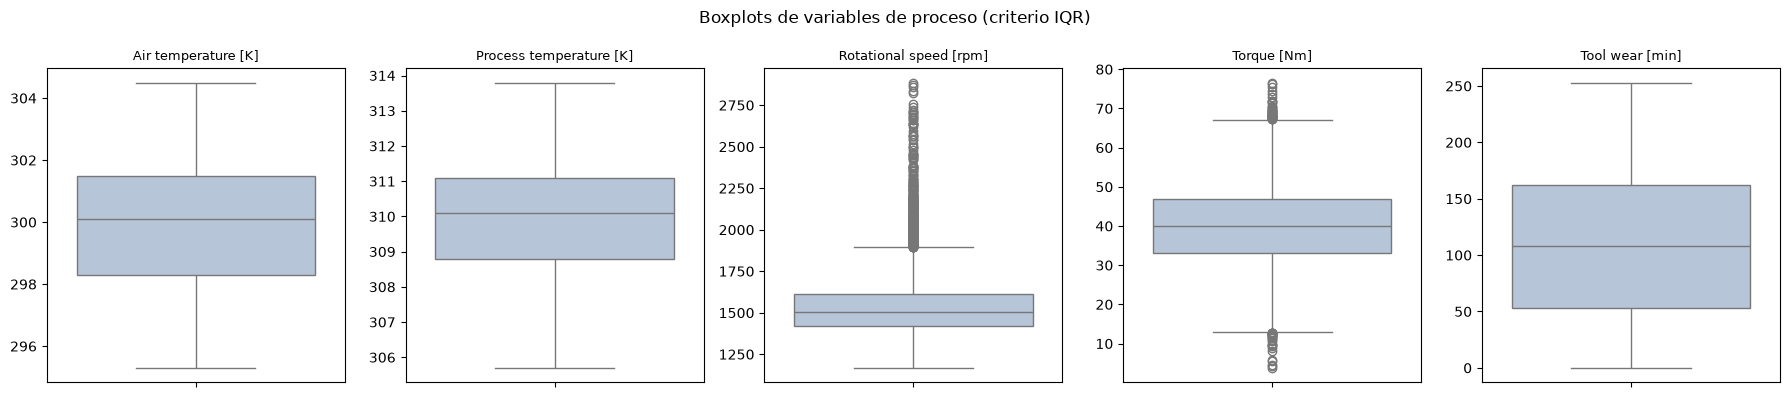

In [13]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

def reporte_outliers(data, columnas):
    filas = []
    for c in columnas:
        q1, q3 = data[c].quantile([0.25, 0.75])
        iqr = q3 - q1
        li, ls = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        m = (data[c] < li) | (data[c] > ls)
        filas.append({"variable": c, "límite_inf": round(li, 2), "límite_sup": round(ls, 2),
                      "outliers": int(m.sum()), "% filas": round(100 * m.mean(), 2),
                      "tasa_falla_en_outliers_%": round(100 * data.loc[m, "Machine failure"].mean(), 1) if m.any() else None})
    return pd.DataFrame(filas)

tabla_outliers = reporte_outliers(csv2, NUMERICAS)
display(tabla_outliers)
print(f"Tasa de falla global: {100 * csv2['Machine failure'].mean():.2f} %")

fig, axes = plt.subplots(1, len(NUMERICAS), figsize=(18, 4))
for ax, c in zip(axes, NUMERICAS):
    sns.boxplot(y=csv2[c], ax=ax, color="lightsteelblue")
    ax.set_title(c, fontsize=9); ax.set_ylabel("")
plt.suptitle("Boxplots de variables de proceso (criterio IQR)")
plt.tight_layout(); plt.show()

**Justificación de la decisión sobre outliers:**

* Las temperaturas y el desgaste **no tienen outliers**.
* `Rotational speed` tiene 418 valores altos (4.2 %) y `Torque` 69 valores extremos (0.7 %). Son valores **físicamente posibles** para una máquina-herramienta, no errores de captura.
* La tasa de falla dentro de los outliers de torque es **89.9 %** (frente a 3.4 % global), y dentro de los de velocidad es 8.4 %. Esos valores extremos **son la señal de falla** (sobreesfuerzo y falla de potencia).

**Decisión:** **no se eliminan ni se recortan**, porque eliminarlos borraría cerca de una de cada cinco fallas del dataset. Los modelos que se usan después son robustos a esto (árboles) o trabajan con datos estandarizados.

### TRANSFORMACIÓN: VARIABLES DERIVADAS Y KPIs INDUSTRIALES
Se crean variables con significado físico, que además corresponden a los mecanismos de falla descritos por el autor del dataset:

| Variable nueva | Fórmula | Significado industrial |
|---|---|---|
| `Power [W]` | Torque × rpm × 2π / 60 | Potencia mecánica entregada. Muy baja o muy alta → falla de potencia (PWF). |
| `Temp diff [K]` | T. proceso − T. aire | Margen de disipación de calor. Diferencia baja + rpm baja → falla por calor (HDF). |
| `Overstrain [min*Nm]` | Desgaste × Torque | Esfuerzo acumulado sobre la herramienta. Valores altos → sobreesfuerzo (OSF). |

In [14]:
csv2["Power [W]"] = csv2["Torque [Nm]"] * csv2["Rotational speed [rpm]"] * 2 * np.pi / 60
csv2["Temp diff [K]"] = csv2["Process temperature [K]"] - csv2["Air temperature [K]"]
csv2["Overstrain [min*Nm]"] = csv2["Tool wear [min]"] * csv2["Torque [Nm]"]

DESCRIPCION.update({
    "Power [W]": ("Potencia mecánica = Torque · rpm · 2π/60", "W", "entrada derivada"),
    "Temp diff [K]": ("Diferencia T. proceso − T. aire (margen de disipación)", "K", "entrada derivada"),
    "Overstrain [min*Nm]": ("Desgaste × torque (esfuerzo acumulado)", "min·Nm", "entrada derivada"),
})

# KPIs industriales del estado actual
kpis = {
    "Ciclos analizados": len(csv2),
    "Tasa de falla global (%)": round(100 * csv2["Machine failure"].mean(), 2),
    "Fallas totales": int(csv2["Machine failure"].sum()),
    "Disponibilidad aprox. (% ciclos sin falla)": round(100 * (1 - csv2["Machine failure"].mean()), 2),
    "Potencia media (W)": round(csv2["Power [W]"].mean(), 0),
    "Desgaste medio en ciclos con falla (min)": round(csv2.loc[csv2["Machine failure"] == 1, "Tool wear [min]"].mean(), 1),
    "Desgaste medio en ciclos sin falla (min)": round(csv2.loc[csv2["Machine failure"] == 0, "Tool wear [min]"].mean(), 1),
}
display(pd.Series(kpis, name="valor").to_frame())

print("Tasa de falla por calidad de producto (%):")
display((100 * csv2.groupby("Type")["Machine failure"].mean()).round(2).to_frame("tasa_falla_%"))
print("Participación de cada modo de falla:")
display(csv2[MODOS].sum().sort_values(ascending=False).to_frame("casos"))

,valor
Ciclos analizados,10000.00
Tasa de falla global (%),3.39
Fallas totales,339.00
Disponibilidad aprox. (% ciclos sin falla),96.61
Potencia media (W),6280.00
Desgaste medio en ciclos con falla (min),143.80
Desgaste medio en ciclos sin falla (min),106.70


Tasa de falla por calidad de producto (%):


,tasa_falla_%
Type,
H,2.09
L,3.92
M,2.77


Participación de cada modo de falla:


,casos
HDF,115
OSF,98
PWF,95
TWF,46
RNF,19


### Diccionario de datos — DESPUÉS de la limpieza y transformación

In [15]:
estado = {"Product ID": "normalizado (mayúsculas, sin espacios)", "Type": "normalizado (mayúsculas, sin espacios)",
          "Power [W]": "NUEVA", "Temp diff [K]": "NUEVA", "Overstrain [min*Nm]": "NUEVA"}
display(diccionario(csv2, estado))
print("Columnas eliminadas: UDI (identificador sin valor predictivo)")

,columna,tipo,unidad,rol,nulos,valores_únicos,ejemplo,descripción,estado
0,Product ID,str,-,id,0,10000,M14860,Código del producto: letra de calidad (L/M/H) ...,"normalizado (mayúsculas, sin espacios)"
1,Type,str,-,entrada categórica,0,3,M,"Calidad del producto: L = baja (50 %), M = med...","normalizado (mayúsculas, sin espacios)"
2,Air temperature [K],float64,K,entrada,0,93,298.1,Temperatura del aire ambiente,sin cambios
3,Process temperature [K],float64,K,entrada,0,82,308.6,Temperatura del proceso,sin cambios
4,Rotational speed [rpm],int64,rpm,entrada,0,941,1551,Velocidad de giro del husillo,sin cambios
5,Torque [Nm],float64,Nm,entrada,0,577,42.8,Torque aplicado,sin cambios
6,Tool wear [min],int64,min,entrada,0,246,0,Minutos de uso acumulados de la herramienta,sin cambios
7,Machine failure,int64,0/1,OBJETIVO,0,2,0,1 si la máquina falló en ese ciclo,sin cambios
8,TWF,int64,0/1,modo de falla,0,2,0,Falla por desgaste de herramienta (tool wear f...,sin cambios
9,HDF,int64,0/1,modo de falla,0,2,0,Falla por disipación de calor (heat dissipatio...,sin cambios


Columnas eliminadas: UDI (identificador sin valor predictivo)


### REPORTE DE CALIDAD DE DATOS

In [16]:
calidad = pd.DataFrame([
    {"chequeo": "Filas", "antes": len(df_original), "después": len(csv2), "acción": "ninguna fila eliminada"},
    {"chequeo": "Columnas", "antes": df_original.shape[1], "después": csv2.shape[1], "acción": "−UDI, +3 variables derivadas"},
    {"chequeo": "Valores nulos", "antes": int(df_original.isna().sum().sum()), "después": int(csv2.isna().sum().sum()), "acción": "dropna (no había)"},
    {"chequeo": "Filas duplicadas", "antes": int(df_original.duplicated().sum()), "después": int(csv2.duplicated().sum()), "acción": "drop_duplicates (no había)"},
    {"chequeo": "Outliers IQR (todas las variables)", "antes": int(tabla_outliers["outliers"].sum()), "después": int(reporte_outliers(csv2, NUMERICAS)["outliers"].sum()), "acción": "se conservan (señal de falla, ver justificación)"},
    {"chequeo": "Formato Type / Product ID", "antes": "texto libre", "después": "mayúsculas, sin espacios", "acción": "normalización"},
    {"chequeo": "Etiqueta incoherente con modos", "antes": int(falla_sin_modo + modo_sin_falla), "después": int(falla_sin_modo + modo_sin_falla), "acción": "se conserva la etiqueta original (documentado)"},
])
display(calidad)

,chequeo,antes,después,acción
0,Filas,10000,10000,ninguna fila eliminada
1,Columnas,14,16,"−UDI, +3 variables derivadas"
2,Valores nulos,0,0,dropna (no había)
3,Filas duplicadas,0,0,drop_duplicates (no había)
4,Outliers IQR (todas las variables),487,487,"se conservan (señal de falla, ver justificación)"
5,Formato Type / Product ID,texto libre,"mayúsculas, sin espacios",normalización
6,Etiqueta incoherente con modos,27,27,se conserva la etiqueta original (documentado)


### MODELO DE DATOS (arquitectura local)

Se usa una arquitectura tipo *data lake* local por capas, con un archivo por capa:

```
datasets/
├── ai4i2020.csv          ← capa RAW: dato original sin modificar (fuente UCI)
└── datos_limpios.csv     ← capa CLEAN: sin UDI, formatos normalizados, + KPIs derivados
notebook (memoria)
└── df_model / X / y      ← capa MODELADO: dummies de Type, sin modos de falla, escalado
```

Visto como modelo relacional, el dato tiene dos entidades:

| Tabla | Clave | Columnas |
|---|---|---|
| **Producto** | `Product ID` (PK) | `Type` |
| **Ciclo_operación** | `UDI` (PK), `Product ID` (FK) | temperaturas, rpm, torque, desgaste, variables derivadas, `Machine failure`, modos de falla |

Como cada `Product ID` aparece una sola vez, la relación es 1:1 y se trabaja con una única tabla plana.

GUARDAR EN UN CSV

In [17]:
print("GUARDAR EN UN CSV")
csv2.to_csv("../datasets/datos_limpios.csv", index=False)

GUARDAR EN UN CSV


In [18]:
df = pd.read_csv("../datasets/datos_limpios.csv")
df.head()

,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF,Power [W],Temp diff [K],Overstrain [min*Nm]
0,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0,6951.590560,10.5,0.0
1,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0,6826.722724,10.5,138.9
2,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0,7749.387543,10.4,247.0
3,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0,5927.504659,10.4,276.5
4,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0,5897.816608,10.5,360.0


LIBRERIAS 

In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             precision_score, recall_score, f1_score, roc_auc_score, silhouette_score)

import warnings; warnings.filterwarnings("ignore")
RANDOM_STATE = 42
SCORING = "f1"   # clases desbalanceadas (3.4 % de fallas): se optimiza F1 de la clase falla, no accuracy

LECTURA DE DATOS (Cvs)

In [20]:
# Archivo y columna objetivo
RUTA_CSV = "../datasets/datos_limpios.csv"   
TARGET = "Machine failure"                   # columna a predecir (0 = no falla, 1 = falla)

df = pd.read_csv(RUTA_CSV)
display(df.head())
df.info()
display(df.describe())
print("Nulos por columna:\n", df.isna().sum())

,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF,Power [W],Temp diff [K],Overstrain [min*Nm]
0,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0,6951.590560,10.5,0.0
1,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0,6826.722724,10.5,138.9
2,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0,7749.387543,10.4,247.0
3,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0,5927.504659,10.4,276.5
4,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0,5897.816608,10.5,360.0


<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 16 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Product ID               10000 non-null  str    
 1   Type                     10000 non-null  str    
 2   Air temperature [K]      10000 non-null  float64
 3   Process temperature [K]  10000 non-null  float64
 4   Rotational speed [rpm]   10000 non-null  int64  
 5   Torque [Nm]              10000 non-null  float64
 6   Tool wear [min]          10000 non-null  int64  
 7   Machine failure          10000 non-null  int64  
 8   TWF                      10000 non-null  int64  
 9   HDF                      10000 non-null  int64  
 10  PWF                      10000 non-null  int64  
 11  OSF                      10000 non-null  int64  
 12  RNF                      10000 non-null  int64  
 13  Power [W]                10000 non-null  float64
 14  Temp diff [K]            10000 non

,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF,Power [W],Temp diff [K],Overstrain [min*Nm]
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190,6279.744953,10.000630,4314.664550
std,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355,1067.418295,1.001094,2826.567692
min,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,1148.440610,7.600000,0.000000
25%,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,5561.184484,9.300000,1963.650000
50%,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,6271.027344,9.800000,4012.950000
75%,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,7003.002724,11.000000,6279.000000
max,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000,10469.923005,12.100000,16497.000000


Nulos por columna:
 Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
Power [W]                  0
Temp diff [K]              0
Overstrain [min*Nm]        0
dtype: int64


## Fase 3 — EDA (análisis exploratorio)

In [21]:
NUM_EDA = NUMERICAS + ["Power [W]", "Temp diff [K]", "Overstrain [min*Nm]"]
desc = df[NUM_EDA].describe().T
desc["asimetría"] = df[NUM_EDA].skew()
desc["curtosis"] = df[NUM_EDA].kurt()
desc["CV_%"] = 100 * desc["std"] / desc["mean"]
display(desc.round(2))

print("Medias por clase (0 = sin falla, 1 = falla):")
display(df.groupby(TARGET)[NUM_EDA].mean().T.round(2))

,count,mean,std,min,25%,50%,75%,max,asimetría,curtosis,CV_%
Air temperature [K],10000.0,300.00,2.00,295.30,298.30,300.10,301.5,304.50,0.11,-0.84,0.67
Process temperature [K],10000.0,310.01,1.48,305.70,308.80,310.10,311.1,313.80,0.02,-0.50,0.48
Rotational speed [rpm],10000.0,1538.78,179.28,1168.00,1423.00,1503.00,1612.0,2886.00,1.99,7.39,11.65
Torque [Nm],10000.0,39.99,9.97,3.80,33.20,40.10,46.8,76.60,-0.01,-0.01,24.93
Tool wear [min],10000.0,107.95,63.65,0.00,53.00,108.00,162.0,253.00,0.03,-1.17,58.97
Power [W],10000.0,6279.74,1067.42,1148.44,5561.18,6271.03,7003.0,10469.92,0.01,0.16,17.00
Temp diff [K],10000.0,10.00,1.00,7.60,9.30,9.80,11.0,12.10,-0.07,-0.99,10.01
Overstrain [min*Nm],10000.0,4314.66,2826.57,0.00,1963.65,4012.95,6279.0,16497.00,0.47,-0.46,65.51


Medias por clase (0 = sin falla, 1 = falla):


Machine failure,0,1
Air temperature [K],299.97,300.89
Process temperature [K],310.00,310.29
Rotational speed [rpm],1540.26,1496.49
Torque [Nm],39.63,50.17
Tool wear [min],106.69,143.78
Power [W],6244.55,7282.82
Temp diff [K],10.02,9.40
Overstrain [min*Nm],4213.84,7187.94


**Interpretación:**
* Las temperaturas casi no varían (CV < 1 %). `Tool wear` y `Overstrain` son las variables más dispersas (CV de 59 % y 66 %).
* `Rotational speed` es la única variable muy asimétrica (asimetría 1.99, curtosis 7.4): tiene una cola de velocidades altas.
* Los ciclos con falla tienen en promedio **+10.5 Nm de torque** (50.2 vs 39.6), **+37 min de desgaste** (143.8 vs 106.7), **+1 000 W de potencia** y **70 % más de esfuerzo acumulado** (Overstrain 7 188 vs 4 214). Su diferencia de temperatura es menor (9.4 vs 10.0 K), lo que indica peor disipación de calor.

### Gráfico 1 — Balance de clases y modos de falla

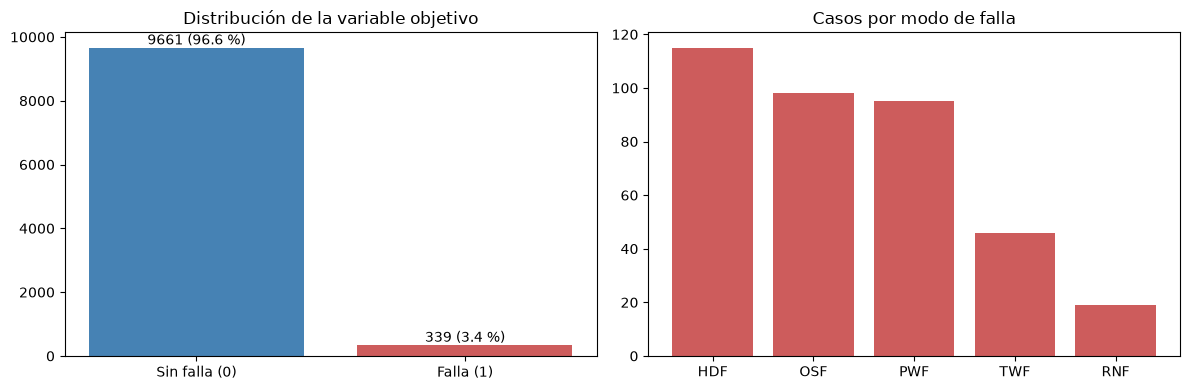

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
conteo = df[TARGET].value_counts().sort_index()
axes[0].bar(["Sin falla (0)", "Falla (1)"], conteo.values, color=["steelblue", "indianred"])
for i, v in enumerate(conteo.values):
    axes[0].text(i, v, f"{v} ({100 * v / len(df):.1f} %)", ha="center", va="bottom")
axes[0].set_title("Distribución de la variable objetivo")
modos = df[MODOS].sum().sort_values(ascending=False)
axes[1].bar(modos.index, modos.values, color="indianred")
axes[1].set_title("Casos por modo de falla")
plt.tight_layout(); plt.show()

**Interpretación:** solo **339 de 10 000 ciclos (3.39 %)** terminan en falla. Las clases están muy desbalanceadas: un modelo que siempre diga "no falla" ya tendría 96.6 % de accuracy. Por eso en la Fase 4 se usan F1, recall y ROC-AUC de la clase falla (H5).

El modo más frecuente es la **falla por disipación de calor (HDF, 115)**, seguido de sobreesfuerzo (OSF, 98) y potencia (PWF, 95). Estos tres explican el 90 % de las fallas y dependen de variables controlables (velocidad, torque, temperatura). El desgaste (TWF, 46) y las fallas aleatorias (RNF, 19) pesan menos.

### Gráfico 2 — Distribución de las variables según falla

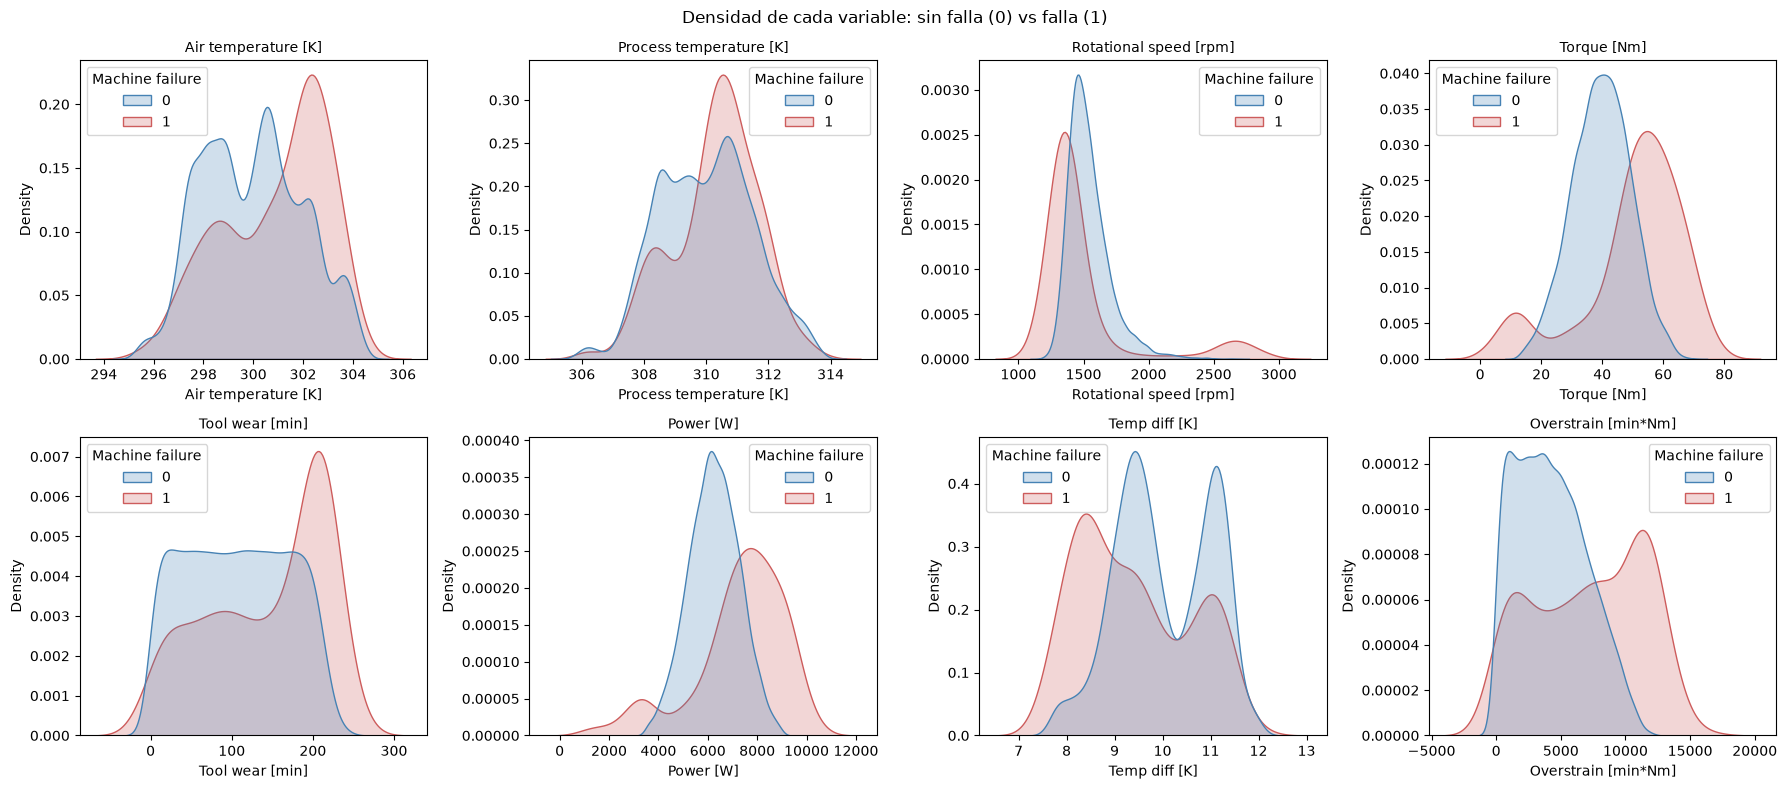

In [23]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, c in zip(axes.ravel(), NUM_EDA):
    sns.kdeplot(data=df, x=c, hue=TARGET, common_norm=False, fill=True, ax=ax, palette=["steelblue", "indianred"])
    ax.set_title(c, fontsize=10)
plt.suptitle("Densidad de cada variable: sin falla (0) vs falla (1)")
plt.tight_layout(); plt.show()

**Interpretación:**
* Las curvas de falla de `Torque`, `Power` y `Overstrain` están desplazadas a la derecha y tienen colas largas. En `Rotational speed` las fallas aparecen en los dos extremos.
* `Tool wear` muestra una acumulación de fallas por encima de ~200 min.
* En las temperaturas las curvas se superponen casi por completo: por sí solas separan poco.
* En `Temp diff`, por debajo de 8.6 K la tasa de falla sube a **17.5 %**, y ahí ocurre el 37 % de todas las fallas.

La relación con la falla **no es lineal**: hay zonas de riesgo en los extremos, lo que sustenta la hipótesis H4.

### Gráfico 3 — Matriz de correlación

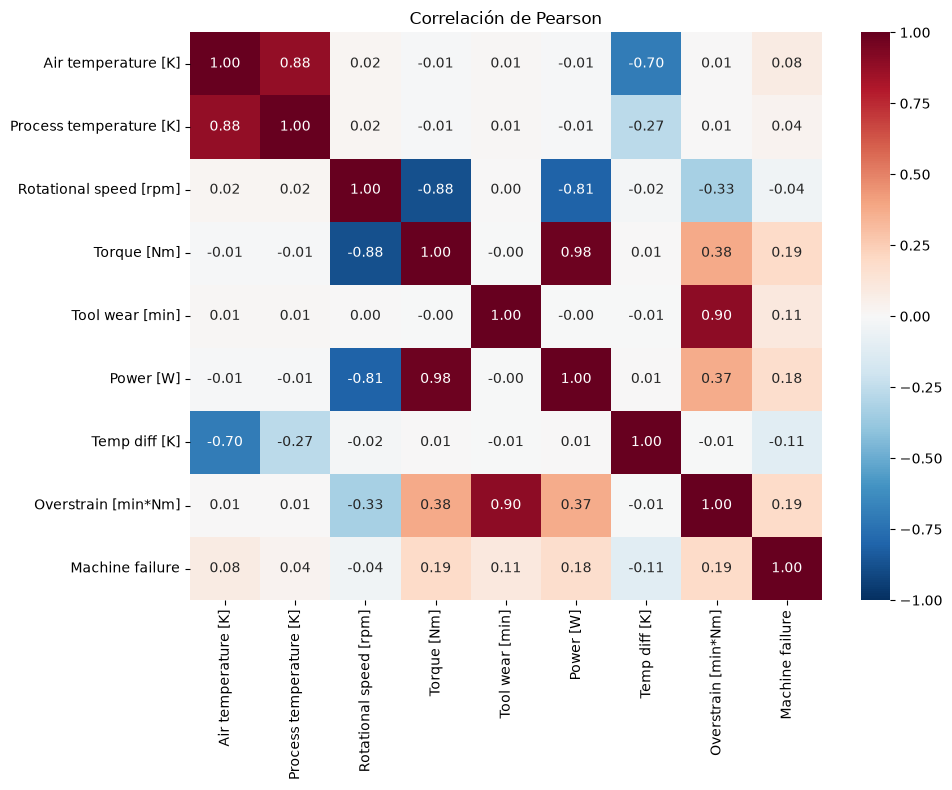

,corr. con falla
Torque [Nm],0.191
Overstrain [min*Nm],0.190
Power [W],0.176
Temp diff [K],-0.112
Tool wear [min],0.105
Air temperature [K],0.083
Rotational speed [rpm],-0.044
Process temperature [K],0.036


In [24]:
plt.figure(figsize=(10, 8))
corr = df[NUM_EDA + [TARGET]].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1)
plt.title("Correlación de Pearson"); plt.tight_layout(); plt.show()
display(corr[TARGET].drop(TARGET).sort_values(key=abs, ascending=False).round(3).to_frame("corr. con falla"))

**Interpretación:**
* Hay **dos pares de variables muy correlacionadas**: T. aire–T. proceso (**0.88**) y rpm–torque (**−0.88**). A eso se suman las derivadas: `Power` con torque (0.98) y `Overstrain` con desgaste (0.90).
* Esa redundancia hace pensar que PCA podría comprimir las variables (H3). También explica por qué los coeficientes de los modelos lineales son inestables.
* Ninguna variable por separado tiene una correlación fuerte con la falla: la mayor es la de torque (0.19). La falla depende de **combinaciones** de variables, no de una sola.

### Gráfico 4 — KPI: tasa de falla por calidad de producto y por desgaste de herramienta

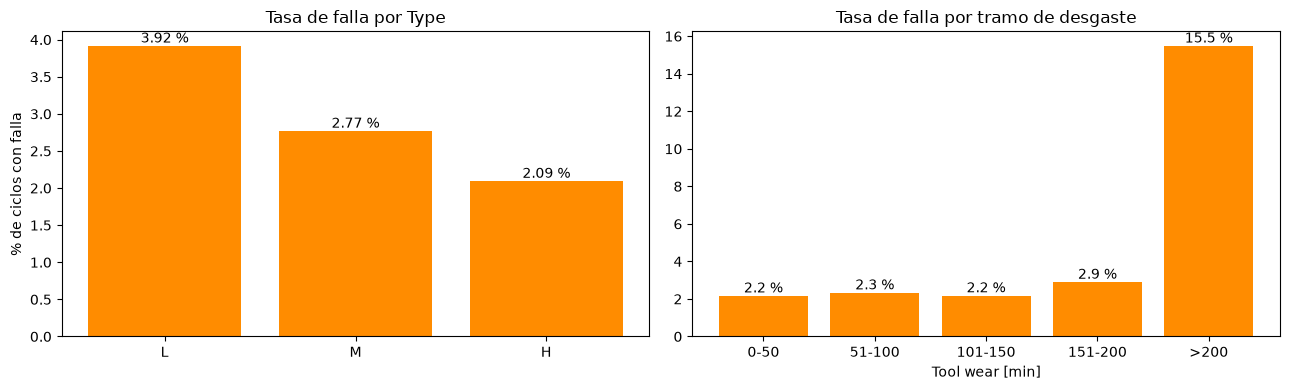

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
tasa_tipo = 100 * df.groupby("Type")[TARGET].mean().reindex(["L", "M", "H"])
axes[0].bar(tasa_tipo.index, tasa_tipo.values, color="darkorange")
for i, v in enumerate(tasa_tipo.values):
    axes[0].text(i, v, f"{v:.2f} %", ha="center", va="bottom")
axes[0].set_title("Tasa de falla por Type"); axes[0].set_ylabel("% de ciclos con falla")

tramos = pd.cut(df["Tool wear [min]"], bins=[-1, 50, 100, 150, 200, 260],
                labels=["0-50", "51-100", "101-150", "151-200", ">200"])
tasa_desgaste = 100 * df.groupby(tramos, observed=True)[TARGET].mean()
axes[1].bar(tasa_desgaste.index.astype(str), tasa_desgaste.values, color="darkorange")
for i, v in enumerate(tasa_desgaste.values):
    axes[1].text(i, v, f"{v:.1f} %", ha="center", va="bottom")
axes[1].set_title("Tasa de falla por tramo de desgaste"); axes[1].set_xlabel("Tool wear [min]")
plt.tight_layout(); plt.show()

**Interpretación (KPIs):**
* **Por calidad:** los productos de calidad **L fallan casi el doble que los H** (3.92 % vs 2.09 %; M = 2.77 %). Como L es el 60 % de la producción, concentra la mayoría de las fallas.
* **Por desgaste:** la tasa de falla se mantiene en ~2–3 % hasta 200 min de uso y **salta a 15.5 % por encima de 200 min**. Esto sugiere un umbral operativo de cambio de herramienta cercano a 200 min.

### Gráfico 5 — Mapa operativo: velocidad vs torque, coloreado por modo de falla

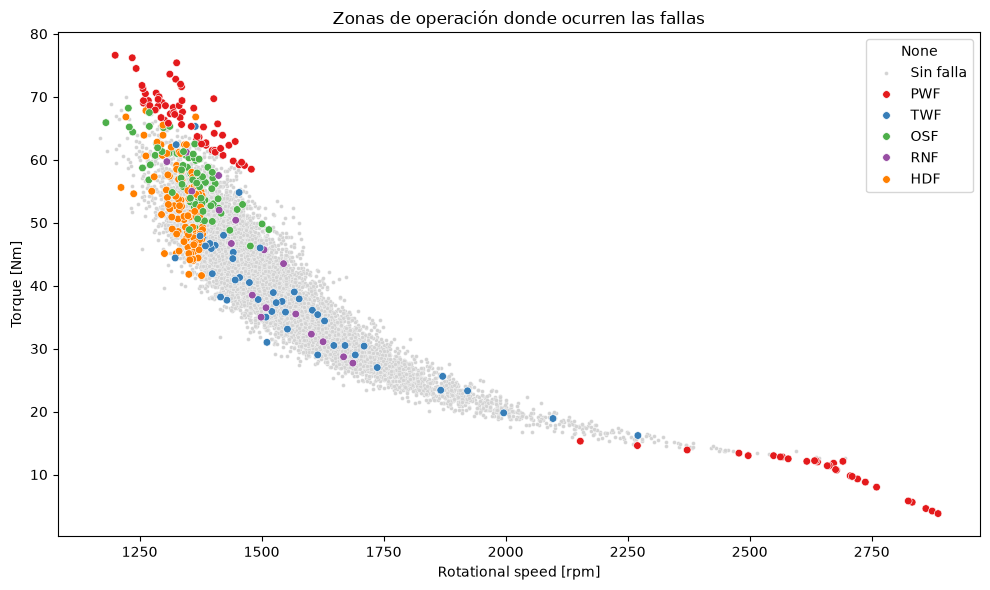

In [26]:
modo = df[MODOS].idxmax(axis=1).where(df[MODOS].sum(axis=1) > 0, "Sin falla")
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df[modo == "Sin falla"], x="Rotational speed [rpm]", y="Torque [Nm]",
                color="lightgray", s=8, label="Sin falla")
sns.scatterplot(data=df[modo != "Sin falla"], x="Rotational speed [rpm]", y="Torque [Nm]",
                hue=modo[modo != "Sin falla"], s=30, palette="Set1")
plt.title("Zonas de operación donde ocurren las fallas"); plt.tight_layout(); plt.show()

**Interpretación:** la operación normal sigue la curva rpm–torque (correlación −0.88). Las fallas aparecen en **zonas extremas** de esa curva:
* **Abajo a la derecha:** velocidad alta y torque bajo, es decir potencia baja → **PWF**.
* **Arriba a la izquierda:** torque alto y velocidad baja → **OSF** (con desgaste alto) y **HDF** (con velocidad baja y poca diferencia de temperatura).

Esto confirma que el riesgo está en los **límites de la ventana de operación**, algo que los modelos de árbol capturan mejor que una frontera lineal (H4).

### Gráfico 6 — Variables derivadas por clase (boxplots)

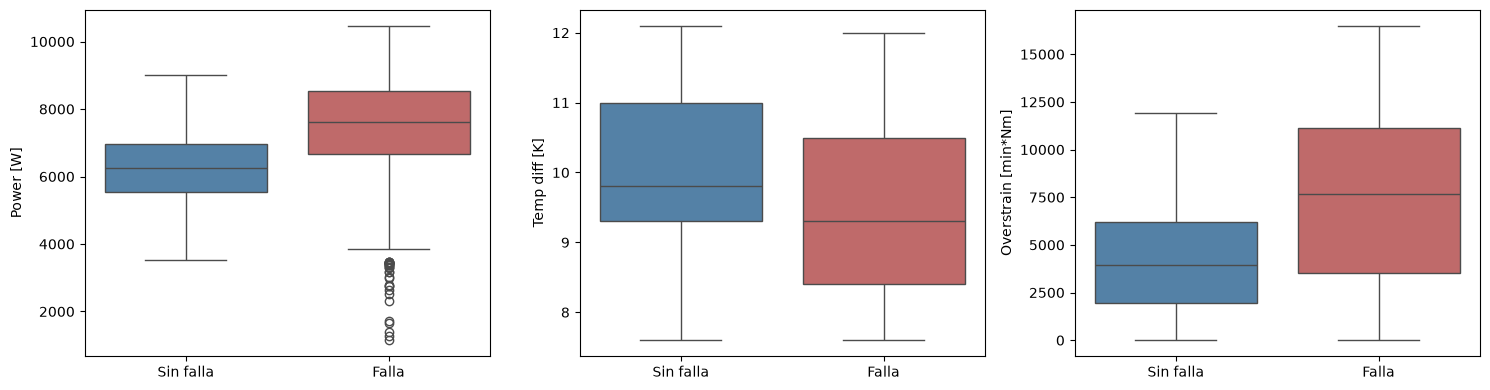

In [27]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, c in zip(axes, ["Power [W]", "Temp diff [K]", "Overstrain [min*Nm]"]):
    sns.boxplot(data=df, x=TARGET, y=c, ax=ax, palette=["steelblue", "indianred"])
    ax.set_xticklabels(["Sin falla", "Falla"]); ax.set_xlabel("")
plt.tight_layout(); plt.show()

**Interpretación:**
* **Potencia:** las fallas tienen más dispersión y muchos valores fuera de la caja, tanto altos como bajos. Coincide con la regla física de PWF (potencia fuera de un rango seguro).
* **Temp diff:** la mediana es menor en las fallas.
* **Overstrain:** la mediana de las fallas es mucho mayor.

Las 3 variables derivadas separan mejor las clases que las originales, lo que justifica haberlas creado en el ETL.

### Hipótesis analíticas (se responden en la Fase 4)

* **H1.** El riesgo de falla depende sobre todo de **torque, desgaste de herramienta y potencia**, más que de las temperaturas por separado → se verifica con la importancia de variables (árbol / Random Forest) y el eje discriminante de LDA.
* **H2.** Existen **regímenes de operación** (combinaciones de rpm/torque/desgaste) con tasas de falla muy distintas → se verifica con clustering.
* **H3.** Como las variables están correlacionadas por pares (temperaturas; rpm–torque), **PCA puede reducir dimensiones sin perder capacidad predictiva** → se verifica comparando modelos con y sin PCA.
* **H4.** Por la relación **no lineal** entre variables y falla (zonas extremas del mapa rpm–torque), los **modelos basados en árboles** superarán a los modelos lineales (Regresión Logística, LDA, Naive Bayes).
* **H5.** Con solo 3.4 % de fallas, el **accuracy no sirve** para elegir modelo: hay que usar F1, recall, ROC-AUC y el costo del error.

## Fase 4 — Modelado analítico

LIMPIEZA, SPLIT Y NORMALIZACIÓN

In [28]:

print("Nulos totales:", df.isna().sum().sum())   # debe dar 0

# Eliminar columnas que no sirven como entrada y codificar categóricas
# Los modos de falla (TWF...RNF) se quitan porque SON la falla: usarlos sería fuga de información.
# Las variables derivadas (Power, Temp diff, Overstrain) sí entran al modelo.
cols_fuera = ["Product ID", "TWF", "HDF", "PWF", "OSF", "RNF"]
df_model = df.drop(columns=cols_fuera)
df_model = pd.get_dummies(df_model, columns=["Type"], drop_first=True, dtype=int)

X = df_model.drop(columns=[TARGET])
y = df_model[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y   # clasificación -> se deja stratify
)

# Normalización: fit SOLO en train, transform en train y test
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s  = scaler.transform(X_test)
print(X_train_s.shape, X_test_s.shape)

Nulos totales: 0
(8000, 10) (2000, 10)


FUNCIÓN AUXILIAR DE EVALUACIÓN  

In [29]:
resultados = {}   # comparación final: nombre del modelo -> métricas

# Costo del error (supuesto declarado): una falla NO detectada (FN) implica parada no planificada,
# pieza dañada y reparación correctiva; una falsa alarma (FP) solo una inspección preventiva.
COSTO_FN = 10
COSTO_FP = 1

def evaluar_modelos_clasificacion(nombre, modelo, Xte=None, yte=None, umbral=None):
    Xte = X_test_s if Xte is None else Xte
    yte = y_test if yte is None else yte
    score = modelo.predict_proba(Xte)[:, 1] if hasattr(modelo, "predict_proba") else modelo.decision_function(Xte)
    pred = modelo.predict(Xte) if umbral is None else (score >= umbral).astype(int)
    tn, fp, fn, tp = confusion_matrix(yte, pred).ravel()
    resultados[nombre] = {
        "accuracy": accuracy_score(yte, pred),
        "precision": precision_score(yte, pred, zero_division=0),
        "recall": recall_score(yte, pred),
        "f1": f1_score(yte, pred),
        "roc_auc": roc_auc_score(yte, score),
        "FN": int(fn), "FP": int(fp),
        "costo": int(COSTO_FN * fn + COSTO_FP * fp),
    }
    r = resultados[nombre]
    print(f"== {nombre} == acc={r['accuracy']:.4f} | F1(falla)={r['f1']:.3f} | recall={r['recall']:.3f} "
          f"| ROC-AUC={r['roc_auc']:.3f} | costo={r['costo']}")
    print(classification_report(yte, pred, zero_division=0))
    sns.heatmap(confusion_matrix(yte, pred), annot=True, fmt="d", cmap="Blues")
    plt.title(nombre); plt.xlabel("Predicho"); plt.ylabel("Real"); plt.show()

MODELOS DE CLASIFICACIÓN/ CLASIFICADOR BAYESIANO (Naive Bayes)

== NaiveBayes base == acc=0.9615 | F1(falla)=0.462 | recall=0.485 | ROC-AUC=0.926 | costo=392
              precision    recall  f1-score   support

           0       0.98      0.98      0.98      1932
           1       0.44      0.49      0.46        68

    accuracy                           0.96      2000
   macro avg       0.71      0.73      0.72      2000
weighted avg       0.96      0.96      0.96      2000



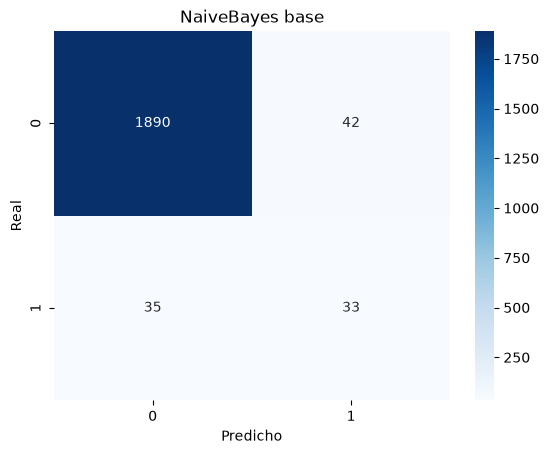

Mejores parámetros: {'var_smoothing': np.float64(0.001)} | CV score: 0.4813432771460989
== NaiveBayes GridSearch == acc=0.9615 | F1(falla)=0.462 | recall=0.485 | ROC-AUC=0.926 | costo=392
              precision    recall  f1-score   support

           0       0.98      0.98      0.98      1932
           1       0.44      0.49      0.46        68

    accuracy                           0.96      2000
   macro avg       0.71      0.73      0.72      2000
weighted avg       0.96      0.96      0.96      2000



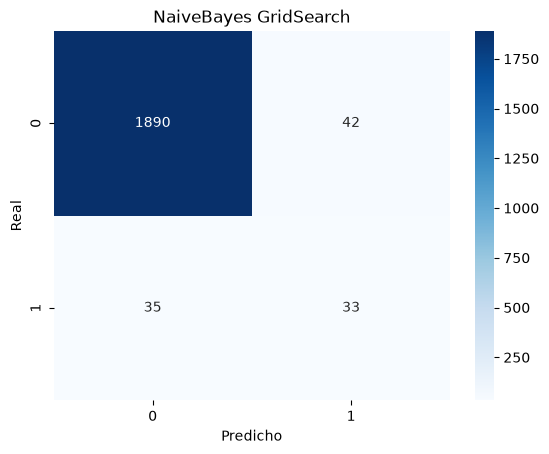

Mejores parámetros: {'var_smoothing': np.float64(0.0001)} | CV score: 0.480411744775349
== NaiveBayes RandomSearch == acc=0.9615 | F1(falla)=0.462 | recall=0.485 | ROC-AUC=0.926 | costo=392
              precision    recall  f1-score   support

           0       0.98      0.98      0.98      1932
           1       0.44      0.49      0.46        68

    accuracy                           0.96      2000
   macro avg       0.71      0.73      0.72      2000
weighted avg       0.96      0.96      0.96      2000



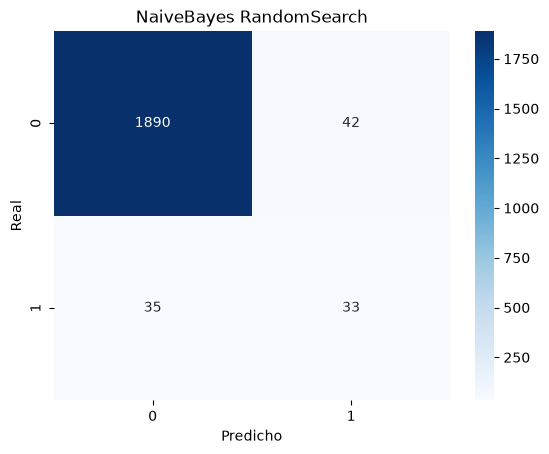

In [30]:
from sklearn.naive_bayes import GaussianNB

# (a) Base entrena GaussianNB con sus valores.
nb = GaussianNB()
nb.fit(X_train_s, y_train)
evaluar_modelos_clasificacion("NaiveBayes base", nb)

# (b) GridSearchCV
param_grid = {"var_smoothing": np.logspace(-12, -3, 10)}
gs = GridSearchCV(GaussianNB(), param_grid, cv=5, scoring=SCORING, n_jobs=-1)
gs.fit(X_train_s, y_train)
print("Mejores parámetros:", gs.best_params_, "| CV score:", gs.best_score_)
evaluar_modelos_clasificacion("NaiveBayes GridSearch", gs.best_estimator_)

# (c) RandomizedSearchCV
rs = RandomizedSearchCV(
    GaussianNB(), param_grid, n_iter=5, cv=5, scoring=SCORING,
    random_state=RANDOM_STATE, n_jobs=-1
)
rs.fit(X_train_s, y_train)
print("Mejores parámetros:", rs.best_params_, "| CV score:", rs.best_score_)
evaluar_modelos_clasificacion("NaiveBayes RandomSearch", rs.best_estimator_)


 K-MEANS (NO SUPERVISADO)

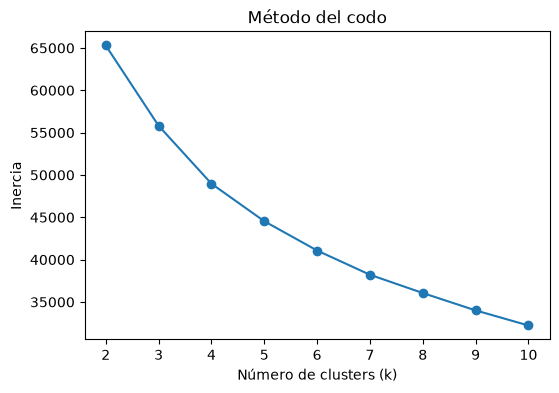

,n_clusters,init,n_init,silhouette
7,3,random,10,0.188644
4,3,k-means++,5,0.188567
5,3,k-means++,10,0.188567
6,3,random,5,0.188526
18,6,random,5,0.186348


Mejor configuración:
 n_clusters           3
init            random
n_init              10
silhouette    0.188644
Name: 7, dtype: object
Adjusted Rand Index vs y_train: -0.006939172893779909
Machine failure     0    1
Cluster                   
0                2212   45
1                3209  193
2                2308   33


In [31]:
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score  
from itertools import product

# Método del codo
inercias = []
ks = range(2, 11)
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE)
    km.fit(X_train_s)
    inercias.append(km.inertia_)

plt.figure(figsize=(6, 4))
plt.plot(ks, inercias, marker="o")
plt.title("Método del codo")
plt.xlabel("Número de clusters (k)")
plt.ylabel("Inercia")
plt.xticks(list(ks))
plt.show()

# Buscar el mejor k con silhouette_score
resultados_km = []
for k, init, n_init in product(range(2, 11), ["k-means++", "random"], [5, 10]):
    km = KMeans(n_clusters=k, init=init, n_init=n_init, random_state=RANDOM_STATE)
    etiquetas = km.fit_predict(X_train_s)
    sil = silhouette_score(X_train_s, etiquetas, sample_size=3000, random_state=RANDOM_STATE)
    resultados_km.append({"n_clusters": k, "init": init, "n_init": n_init, "silhouette": sil})

df_km = pd.DataFrame(resultados_km).sort_values("silhouette", ascending=False)
display(df_km.head())

mejor = df_km.iloc[0]
print("Mejor configuración:\n", mejor)

# Modelo final con la mejor configuración
km_final = KMeans(
    n_clusters=int(mejor["n_clusters"]), init=mejor["init"],
    n_init=int(mejor["n_init"]), random_state=RANDOM_STATE
)
etiquetas_final = km_final.fit_predict(X_train_s)

# Comparar los clusters contra la respuesta real (y_train)
print("Adjusted Rand Index vs y_train:", adjusted_rand_score(y_train, etiquetas_final))
print(pd.crosstab(etiquetas_final, y_train, rownames=["Cluster"], colnames=["Machine failure"]))

### Perfil de los clusters con las variables originales

In [32]:
perfil = X_train.copy()
perfil["cluster"] = etiquetas_final
perfil["tasa_falla_%"] = 100 * y_train.values
tabla_perfil = perfil.groupby("cluster").mean().T.round(2)
tabla_perfil.loc["n_ciclos"] = perfil["cluster"].value_counts().sort_index()
display(tabla_perfil)

cluster,0,1,2
Air temperature [K],299.97,299.89,300.21
Process temperature [K],309.99,309.94,310.12
Rotational speed [rpm],1496.31,1442.54,1721.56
Torque [Nm],41.76,46.10,29.45
Tool wear [min],104.49,119.94,92.96
Power [W],6460.29,6918.45,5187.31
Temp diff [K],10.02,10.05,9.91
Overstrain [min*Nm],4321.58,5434.52,2639.65
Type_L,0.00,0.88,0.78
Type_M,0.95,0.00,0.10


**Justificación de k e interpretación del perfil:** con todas las variables (incluidas las dummies de `Type`), el mejor silhouette es **k = 3 (0.19)**. Es un valor bajo: los grupos se solapan, lo esperable en datos de proceso continuos.

Los clusters se explican sobre todo por la **calidad del producto** y por la **carga de trabajo**:

| Cluster | Perfil | Tasa de falla |
|---|---|---|
| 0 | Productos **M**, carga media (41.8 Nm, 1 496 rpm) | 2.0 % |
| 1 | Productos **L**, **carga alta** (46.1 Nm, 1 443 rpm, desgaste 120 min) | **5.7 %** |
| 2 | Productos L/M a **alta velocidad y bajo torque** (1 722 rpm, 29.5 Nm) | 1.4 % |

El ARI frente a `Machine failure` es ≈ 0: K-means **no reproduce la etiqueta de falla**, y no se espera que lo haga porque no es supervisado. Aun así, el cluster 1 tiene un riesgo **4 veces mayor** que el cluster 2. **Significado de negocio:** los lotes L procesados con mucho torque son el segmento a vigilar.

### Segmentación por régimen de operación (solo variables de proceso)
Para responder H2 se repite K-means **solo con las variables de operación** (sin `Type`), de modo que los grupos representen formas de operar la máquina.

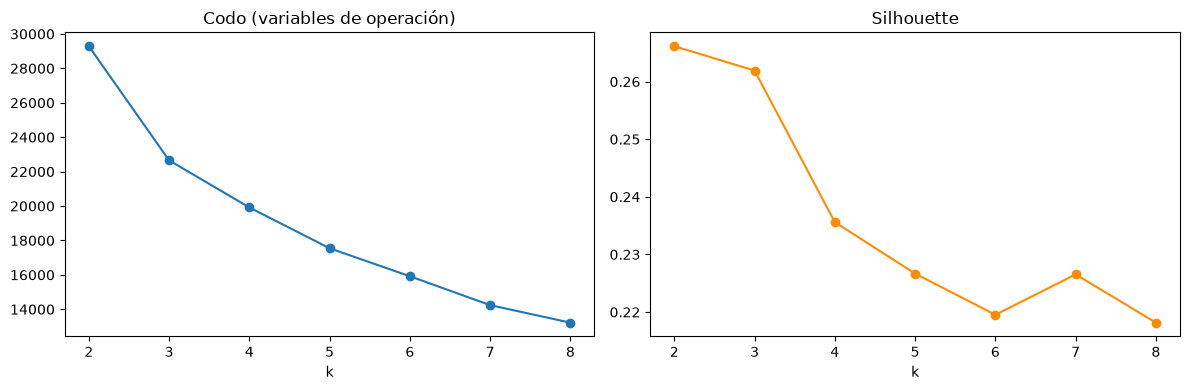

,2,3,4,5,6,7,8
silhouette,0.266,0.262,0.236,0.227,0.22,0.227,0.218


,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Power [W],Overstrain [min*Nm],tasa_falla_%,n_ciclos
cluster,,,,,,,,,
0,301.3,311.0,1487.1,42.4,170.8,6524.9,7236.4,6.2,1862
1,298.1,308.6,1477.2,43.1,102.2,6601.8,4405.0,1.8,2882
2,301.7,311.2,1473.9,43.5,55.0,6643.0,2417.2,3.7,1878
3,300.0,310.0,1829.3,25.5,105.6,4796.5,2694.3,2.4,1378


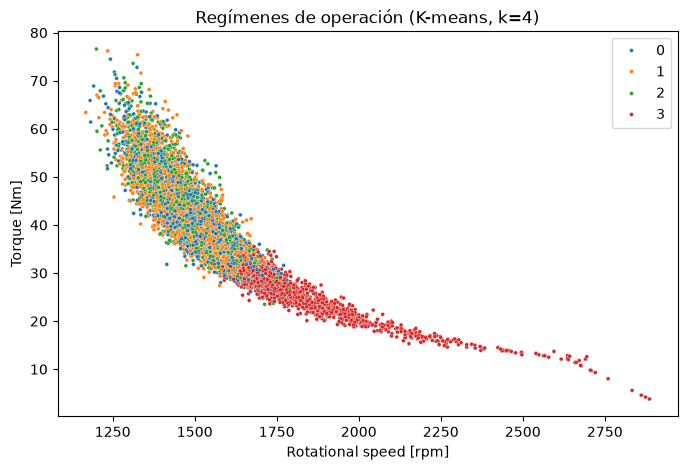

In [33]:
VARS_OP = ["Air temperature [K]", "Process temperature [K]", "Rotational speed [rpm]", "Torque [Nm]", "Tool wear [min]"]
idx_op = [X.columns.get_loc(c) for c in VARS_OP]
X_op = X_train_s[:, idx_op]

sil_op, inercia_op = {}, {}
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_op)
    inercia_op[k] = km.inertia_
    sil_op[k] = silhouette_score(X_op, km.labels_, sample_size=3000, random_state=RANDOM_STATE)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(list(inercia_op), list(inercia_op.values()), marker="o"); axes[0].set_title("Codo (variables de operación)")
axes[1].plot(list(sil_op), list(sil_op.values()), marker="o", color="darkorange"); axes[1].set_title("Silhouette")
for ax in axes: ax.set_xlabel("k")
plt.tight_layout(); plt.show()
display(pd.Series(sil_op, name="silhouette").round(3).to_frame().T)

K_OP = 4   # k=2 tiene el silhouette más alto pero solo separa por temperatura; k=4 (casi igual) da regímenes accionables
km_op = KMeans(n_clusters=K_OP, n_init=10, random_state=RANDOM_STATE).fit(X_op)
perfil_op = X_train[VARS_OP + ["Power [W]", "Overstrain [min*Nm]"]].copy()
perfil_op["cluster"] = km_op.labels_
perfil_op["tasa_falla_%"] = 100 * y_train.values
tabla_op = perfil_op.groupby("cluster").mean().round(1)
tabla_op["n_ciclos"] = perfil_op["cluster"].value_counts().sort_index()
display(tabla_op)

plt.figure(figsize=(8, 5))
sns.scatterplot(x=X_train["Rotational speed [rpm]"], y=X_train["Torque [Nm]"], hue=km_op.labels_, palette="tab10", s=8)
plt.title(f"Regímenes de operación (K-means, k={K_OP})"); plt.show()

**Justificación de k:** el silhouette máximo es k = 2 (0.266), pero ese corte solo separa días "fríos" de "cálidos". Se elige **k = 4 (0.236, apenas 0.03 menos)** porque además separa por desgaste y por velocidad, y da segmentos accionables.

| Régimen | Perfil (variables originales) | Tasa de falla |
|---|---|---|
| Cálido + herramienta gastada | T. aire ≈ 301.3 K, desgaste ≈ 171 min | **6.2 %** |
| Cálido + herramienta nueva | T. aire ≈ 301.7 K, desgaste ≈ 55 min | 3.7 % |
| Alta velocidad / bajo torque | ≈ 1 830 rpm, 25.5 Nm | 2.4 % |
| Frío, carga normal | T. aire ≈ 298.1 K | **1.8 %** |

**H2 se confirma:** hay regímenes de operación con riesgo de falla **3.4 veces distinto** (6.2 % vs 1.8 %). La combinación de **temperatura ambiente alta y desgaste alto** es la de mayor riesgo, coherente con los modos HDF y TWF/OSF.

PCA

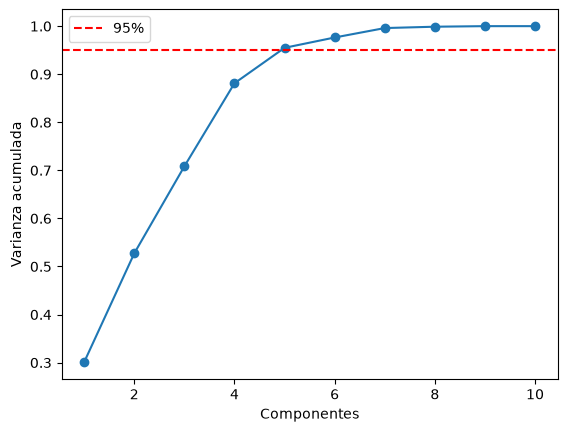

Componentes para >= 95% de varianza: 5 | varianza: 0.95490268685015
== NaiveBayes sin PCA == acc=0.9615 | F1(falla)=0.462 | recall=0.485 | ROC-AUC=0.926 | costo=392
              precision    recall  f1-score   support

           0       0.98      0.98      0.98      1932
           1       0.44      0.49      0.46        68

    accuracy                           0.96      2000
   macro avg       0.71      0.73      0.72      2000
weighted avg       0.96      0.96      0.96      2000



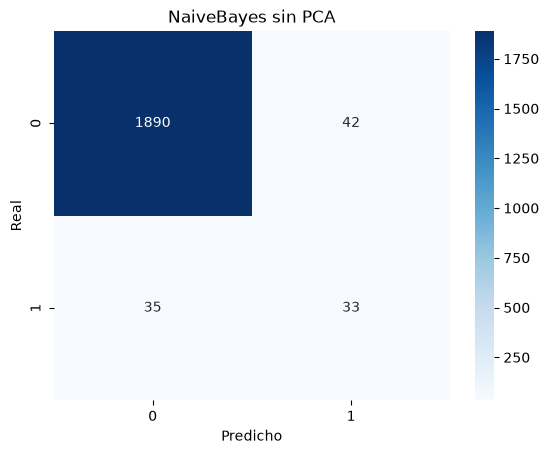

== NaiveBayes con PCA (5 comp.) == acc=0.9685 | F1(falla)=0.160 | recall=0.088 | ROC-AUC=0.925 | costo=621
              precision    recall  f1-score   support

           0       0.97      1.00      0.98      1932
           1       0.86      0.09      0.16        68

    accuracy                           0.97      2000
   macro avg       0.91      0.54      0.57      2000
weighted avg       0.97      0.97      0.96      2000



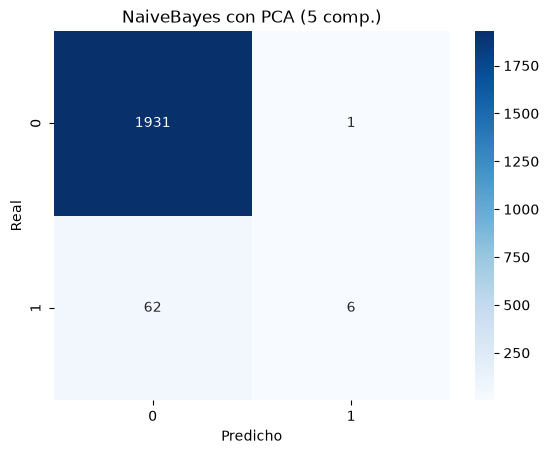

== RegLogistica sin PCA == acc=0.9675 | F1(falla)=0.270 | recall=0.176 | ROC-AUC=0.925 | costo=569
              precision    recall  f1-score   support

           0       0.97      1.00      0.98      1932
           1       0.57      0.18      0.27        68

    accuracy                           0.97      2000
   macro avg       0.77      0.59      0.63      2000
weighted avg       0.96      0.97      0.96      2000



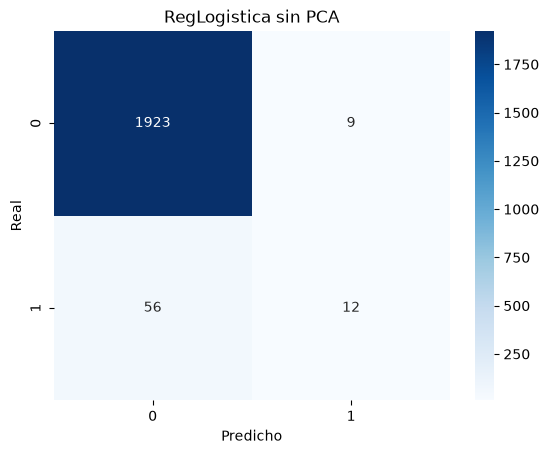

== RegLogistica con PCA (5 comp.) == acc=0.9660 | F1(falla)=0.000 | recall=0.000 | ROC-AUC=0.832 | costo=680
              precision    recall  f1-score   support

           0       0.97      1.00      0.98      1932
           1       0.00      0.00      0.00        68

    accuracy                           0.97      2000
   macro avg       0.48      0.50      0.49      2000
weighted avg       0.93      0.97      0.95      2000



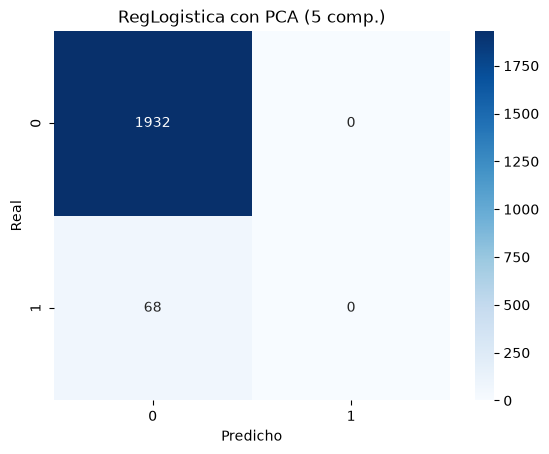

Mejor n_components: {'pca__n_components': 9} | CV score: 0.36336108336108336
== RegLogistica PCA GridSearch == acc=0.9675 | F1(falla)=0.270 | recall=0.176 | ROC-AUC=0.925 | costo=569
              precision    recall  f1-score   support

           0       0.97      1.00      0.98      1932
           1       0.57      0.18      0.27        68

    accuracy                           0.97      2000
   macro avg       0.77      0.59      0.63      2000
weighted avg       0.96      0.97      0.96      2000



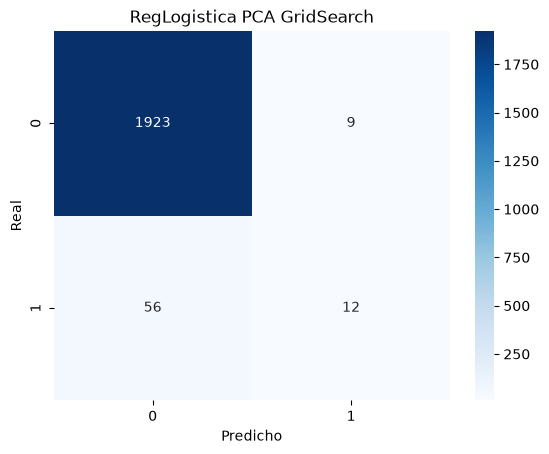

,accuracy,precision,recall,f1,roc_auc,FN,FP,costo
NaiveBayes base,0.962,0.440,0.485,0.462,0.926,35.0,42.0,392.0
NaiveBayes GridSearch,0.962,0.440,0.485,0.462,0.926,35.0,42.0,392.0
NaiveBayes RandomSearch,0.962,0.440,0.485,0.462,0.926,35.0,42.0,392.0
NaiveBayes sin PCA,0.962,0.440,0.485,0.462,0.926,35.0,42.0,392.0
RegLogistica sin PCA,0.968,0.571,0.176,0.270,0.925,56.0,9.0,569.0
RegLogistica PCA GridSearch,0.968,0.571,0.176,0.270,0.925,56.0,9.0,569.0
NaiveBayes con PCA (5 comp.),0.968,0.857,0.088,0.160,0.925,62.0,1.0,621.0
RegLogistica con PCA (5 comp.),0.966,0.000,0.000,0.000,0.832,68.0,0.0,680.0


In [34]:
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB

# Varianza explicada
pca = PCA().fit(X_train_s)
var_acum = np.cumsum(pca.explained_variance_ratio_)

plt.plot(range(1, len(var_acum) + 1), var_acum, marker="o")
plt.axhline(0.95, color="red", linestyle="--", label="95%")
plt.xlabel("Componentes"); plt.ylabel("Varianza acumulada")
plt.legend(); plt.show()

# Número de componentes que explica al menos el 95% de la varianza
n_95 = int(np.argmax(var_acum >= 0.95) + 1)
print("Componentes para >= 95% de varianza:", n_95, "| varianza:", var_acum[n_95 - 1])

# Modelos de clasificación, con y sin PCA
modelos = {
    "NaiveBayes": GaussianNB(),
    "RegLogistica": LogisticRegression(random_state=RANDOM_STATE, max_iter=1000),
}

for nombre, modelo in modelos.items():
    # Sin PCA
    modelo.fit(X_train_s, y_train)
    evaluar_modelos_clasificacion(f"{nombre} sin PCA", modelo)

    # Con PCA (Pipeline: primero PCA, luego el clasificador)
    pipe = Pipeline([
        ("pca", PCA(n_components=n_95)),
        ("clf", type(modelo)(**modelo.get_params())),
    ])
    pipe.fit(X_train_s, y_train)
    evaluar_modelos_clasificacion(f"{nombre} con PCA ({n_95} comp.)", pipe)

# Afinar n_components con GridSearchCV
pipe = Pipeline([("pca", PCA()), ("clf", LogisticRegression(random_state=RANDOM_STATE, max_iter=1000))])
gs_pca = GridSearchCV(pipe, {"pca__n_components": range(1, X_train_s.shape[1] + 1)},
                      cv=5, scoring=SCORING, n_jobs=-1)
gs_pca.fit(X_train_s, y_train)
print("Mejor n_components:", gs_pca.best_params_, "| CV score:", gs_pca.best_score_)
evaluar_modelos_clasificacion("RegLogistica PCA GridSearch", gs_pca.best_estimator_)

# Comparación final
display(pd.DataFrame(resultados).T.sort_values("f1", ascending=False).round(3))

### Loadings de PCA y visualización 2D

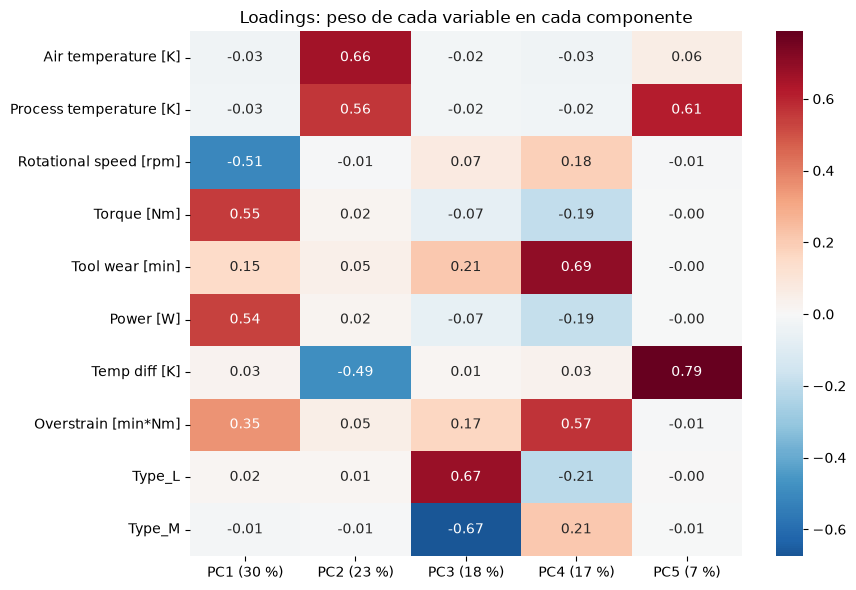

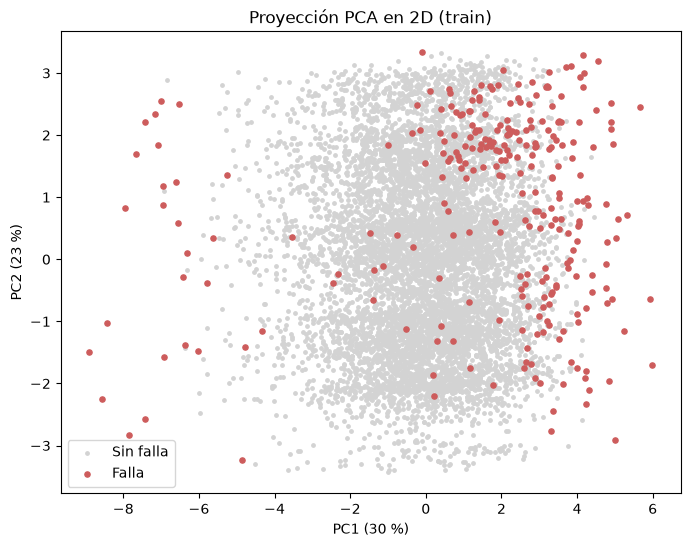

In [35]:
pca_n = PCA(n_components=n_95).fit(X_train_s)
loadings = pd.DataFrame(pca_n.components_.T, index=X.columns,
                        columns=[f"PC{i + 1} ({100 * v:.0f} %)" for i, v in enumerate(pca_n.explained_variance_ratio_)])
plt.figure(figsize=(9, 6))
sns.heatmap(loadings, annot=True, fmt=".2f", cmap="RdBu_r", center=0)
plt.title("Loadings: peso de cada variable en cada componente"); plt.tight_layout(); plt.show()

Z = pca_n.transform(X_train_s)
plt.figure(figsize=(8, 6))
plt.scatter(Z[y_train.values == 0, 0], Z[y_train.values == 0, 1], s=6, c="lightgray", label="Sin falla")
plt.scatter(Z[y_train.values == 1, 0], Z[y_train.values == 1, 1], s=14, c="indianred", label="Falla")
plt.xlabel(loadings.columns[0]); plt.ylabel(loadings.columns[1]); plt.legend()
plt.title("Proyección PCA en 2D (train)"); plt.show()

**Varianza explicada y número de componentes:** con 5 componentes se explica el **95.5 %** de la varianza (de 10 variables). La reducción tiene sentido porque hay pares muy correlacionados.

**Interpretación de los loadings:**
* **PC1 (30 %) — "carga mecánica":** torque (+0.55), potencia (+0.54) y overstrain (+0.35) frente a rpm (−0.51).
* **PC2 (23 %) — "temperatura":** T. aire (+0.66), T. proceso (+0.56) y Temp diff (−0.49).
* **PC3 (18 %) — "calidad del producto":** Type_L (+0.67) frente a Type_M (−0.67).
* **PC4 (17 %) — "desgaste":** tool wear (+0.69) y overstrain (+0.57).
* **PC5 (7 %) — "margen térmico":** Temp diff (+0.79) y T. proceso (+0.61).

**Uso de PCA:**
* **Visualización 2D:** en el plano PC1–PC2 las fallas se desplazan hacia PC1 alto (carga mecánica alta; mediana 2.5 frente a 0.0 de los ciclos normales) y PC2 alto (ambiente cálido). Hay un grupo pequeño en PC1 muy bajo (potencia baja → PWF). Aun así se mezclan con los ciclos normales.
* **Preprocesamiento (H3 se rechaza):** reducir a 5 componentes **empeora** la clasificación. La Regresión Logística baja de F1 0.27 a 0.00 y Naive Bayes de 0.46 a 0.16. El GridSearch elige 9 de 10 componentes, es decir, casi ninguna reducción.

PCA no usa la variable objetivo, y la información que separa las fallas está en direcciones de **poca varianza** (el 4.5 % descartado). Para este problema PCA sirve para **interpretar y visualizar**, no para preprocesar.

LDA

== LDA base == acc=0.9665 | F1(falla)=0.437 | recall=0.382 | ROC-AUC=0.904 | costo=445
              precision    recall  f1-score   support

           0       0.98      0.99      0.98      1932
           1       0.51      0.38      0.44        68

    accuracy                           0.97      2000
   macro avg       0.74      0.68      0.71      2000
weighted avg       0.96      0.97      0.96      2000



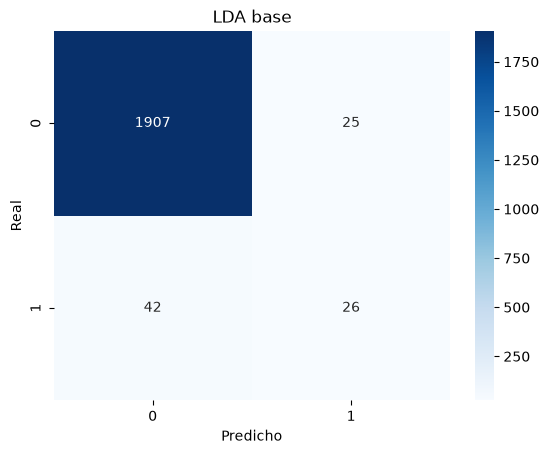

Mejores parámetros: {'shrinkage': 'auto', 'solver': 'lsqr'} | CV score: 0.4457918029561722
== LDA GridSearch == acc=0.9670 | F1(falla)=0.431 | recall=0.368 | ROC-AUC=0.898 | costo=453
              precision    recall  f1-score   support

           0       0.98      0.99      0.98      1932
           1       0.52      0.37      0.43        68

    accuracy                           0.97      2000
   macro avg       0.75      0.68      0.71      2000
weighted avg       0.96      0.97      0.96      2000



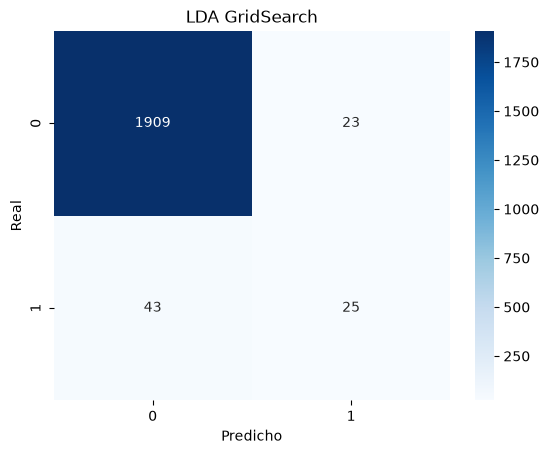

In [36]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

# Base
lda = LinearDiscriminantAnalysis()
lda.fit(X_train_s, y_train)
evaluar_modelos_clasificacion("LDA base", lda)

# GridSearchCV sobre solver y shrinkage
param_grid = [
    {"solver": ["svd"]},
    {"solver": ["lsqr", "eigen"], "shrinkage": [None, "auto", 0.1, 0.5, 0.9]},
]
gs_lda = GridSearchCV(LinearDiscriminantAnalysis(), param_grid, cv=5, scoring=SCORING, n_jobs=-1)
gs_lda.fit(X_train_s, y_train)
print("Mejores parámetros:", gs_lda.best_params_, "| CV score:", gs_lda.best_score_)
evaluar_modelos_clasificacion("LDA GridSearch", gs_lda.best_estimator_)

### LDA como reducción supervisada antes de clasificar
Con 2 clases LDA produce **un solo eje discriminante** (LD1). Se proyectan los datos sobre LD1 y se entrena un clasificador encima; se compara contra el mismo clasificador sin LDA.

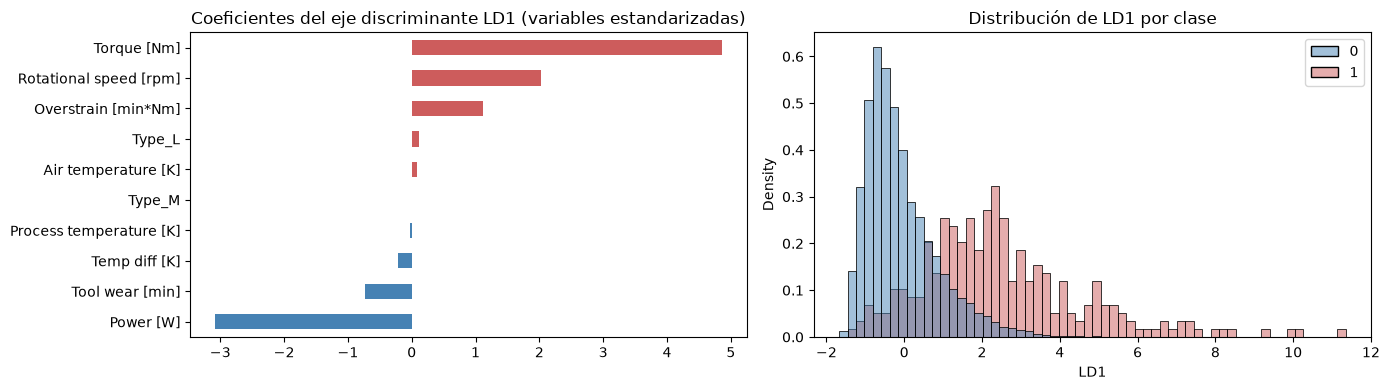

== RegLogistica sin LDA == acc=0.9675 | F1(falla)=0.270 | recall=0.176 | ROC-AUC=0.925 | costo=569
              precision    recall  f1-score   support

           0       0.97      1.00      0.98      1932
           1       0.57      0.18      0.27        68

    accuracy                           0.97      2000
   macro avg       0.77      0.59      0.63      2000
weighted avg       0.96      0.97      0.96      2000



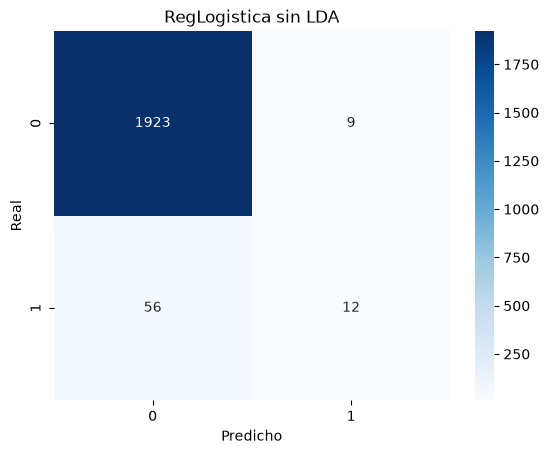

== RegLogistica con LDA (LD1) == acc=0.9680 | F1(falla)=0.238 | recall=0.147 | ROC-AUC=0.904 | costo=586
              precision    recall  f1-score   support

           0       0.97      1.00      0.98      1932
           1       0.62      0.15      0.24        68

    accuracy                           0.97      2000
   macro avg       0.80      0.57      0.61      2000
weighted avg       0.96      0.97      0.96      2000



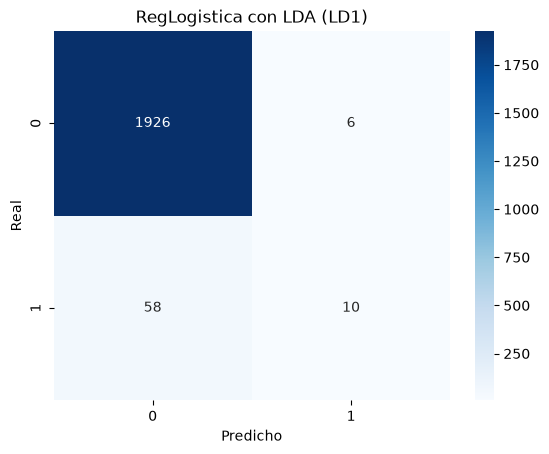

== kNN sin LDA == acc=0.9745 | F1(falla)=0.440 | recall=0.294 | ROC-AUC=0.867 | costo=483
              precision    recall  f1-score   support

           0       0.98      1.00      0.99      1932
           1       0.87      0.29      0.44        68

    accuracy                           0.97      2000
   macro avg       0.92      0.65      0.71      2000
weighted avg       0.97      0.97      0.97      2000



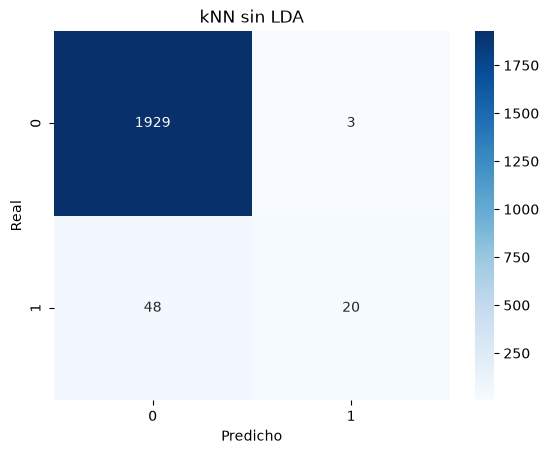

== kNN con LDA (LD1) == acc=0.9650 | F1(falla)=0.239 | recall=0.162 | ROC-AUC=0.729 | costo=583
              precision    recall  f1-score   support

           0       0.97      0.99      0.98      1932
           1       0.46      0.16      0.24        68

    accuracy                           0.96      2000
   macro avg       0.71      0.58      0.61      2000
weighted avg       0.95      0.96      0.96      2000



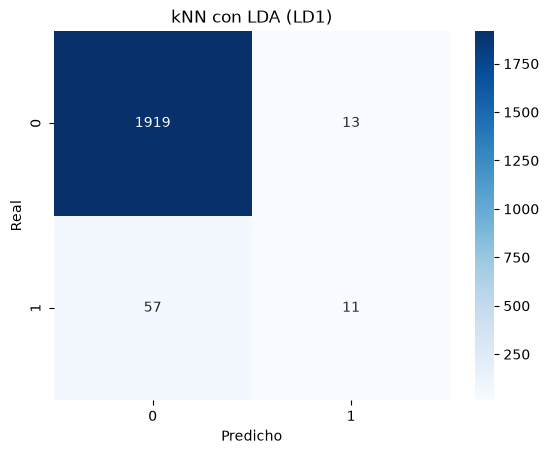

== NaiveBayes sin LDA == acc=0.9615 | F1(falla)=0.462 | recall=0.485 | ROC-AUC=0.926 | costo=392
              precision    recall  f1-score   support

           0       0.98      0.98      0.98      1932
           1       0.44      0.49      0.46        68

    accuracy                           0.96      2000
   macro avg       0.71      0.73      0.72      2000
weighted avg       0.96      0.96      0.96      2000



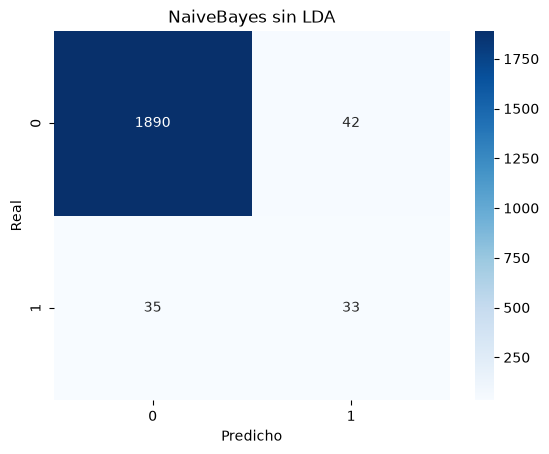

== NaiveBayes con LDA (LD1) == acc=0.9665 | F1(falla)=0.407 | recall=0.338 | ROC-AUC=0.898 | costo=472
              precision    recall  f1-score   support

           0       0.98      0.99      0.98      1932
           1       0.51      0.34      0.41        68

    accuracy                           0.97      2000
   macro avg       0.74      0.66      0.69      2000
weighted avg       0.96      0.97      0.96      2000



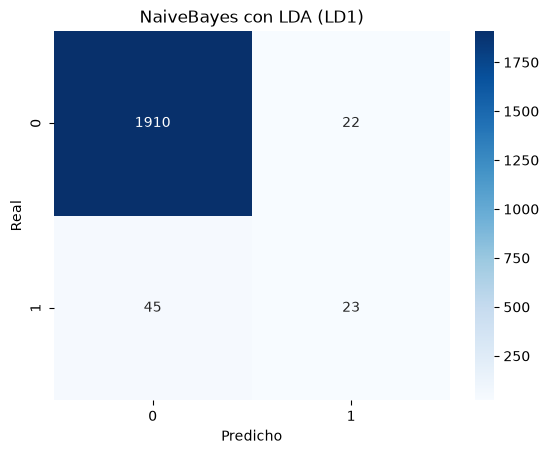

,accuracy,precision,recall,f1,roc_auc,costo
RegLogistica sin LDA,0.968,0.571,0.176,0.270,0.925,569.0
RegLogistica con LDA (LD1),0.968,0.625,0.147,0.238,0.904,586.0
kNN sin LDA,0.974,0.870,0.294,0.440,0.867,483.0
kNN con LDA (LD1),0.965,0.458,0.162,0.239,0.729,583.0
NaiveBayes sin LDA,0.962,0.440,0.485,0.462,0.926,392.0
NaiveBayes con LDA (LD1),0.966,0.511,0.338,0.407,0.898,472.0


In [37]:
from sklearn.base import clone
from sklearn.neighbors import KNeighborsClassifier

lda_eje = LinearDiscriminantAnalysis().fit(X_train_s, y_train)
coef_lda = pd.Series(lda_eje.scalings_[:, 0], index=X.columns).sort_values()
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
coef_lda.plot.barh(ax=axes[0], color=["indianred" if v > 0 else "steelblue" for v in coef_lda])
axes[0].set_title("Coeficientes del eje discriminante LD1 (variables estandarizadas)")
ld1 = lda_eje.transform(X_train_s)[:, 0]
sns.histplot(x=ld1, hue=y_train.values, stat="density", common_norm=False, bins=60, ax=axes[1], palette=["steelblue", "indianred"])
axes[1].set_title("Distribución de LD1 por clase"); axes[1].set_xlabel("LD1")
plt.tight_layout(); plt.show()

clasificadores = {
    "RegLogistica": LogisticRegression(random_state=RANDOM_STATE, max_iter=1000),
    "kNN": KNeighborsClassifier(n_neighbors=5),
    "NaiveBayes": GaussianNB(),
}
nombres_lda = []
for nombre, clf in clasificadores.items():
    m = clone(clf).fit(X_train_s, y_train)
    evaluar_modelos_clasificacion(f"{nombre} sin LDA", m)
    pipe = Pipeline([("lda", LinearDiscriminantAnalysis(n_components=1)), ("clf", clone(clf))]).fit(X_train_s, y_train)
    evaluar_modelos_clasificacion(f"{nombre} con LDA (LD1)", pipe)
    nombres_lda += [f"{nombre} sin LDA", f"{nombre} con LDA (LD1)"]

display(pd.DataFrame(resultados).T.loc[nombres_lda, ["accuracy", "precision", "recall", "f1", "roc_auc", "costo"]].round(3))

**Interpretación del eje discriminante (LD1):** los mayores coeficientes positivos (dirección "falla") son **Torque (+4.86)**, **rpm (+2.03)** y **Overstrain (+1.11)**. El mayor negativo es **Power (−3.08)**. Como Power ≈ torque × rpm, el eje mide en realidad **cuánto se aleja la combinación torque/velocidad de la potencia "normal"**, junto con el esfuerzo acumulado sobre la herramienta. Las temperaturas y `Type` casi no pesan.

El histograma de LD1 muestra las fallas desplazadas a la derecha pero con mucho solapamiento: un solo eje lineal no basta para separar las clases.

**Con vs sin LDA:** usar LDA como reducción a 1 dimensión **empeora** a los tres clasificadores:

| Modelo | F1 sin LDA | F1 con LDA |
|---|---|---|
| Regresión Logística | 0.27 | 0.24 |
| kNN | 0.44 | 0.24 |
| Naive Bayes | 0.46 | 0.41 |

Comprimir 10 variables en un único eje lineal descarta las relaciones no lineales que se vieron en el EDA (zonas extremas del mapa rpm–torque). LDA es útil para **explicar qué variables discriminan**, pero no como paso previo a clasificar en este problema.

ARBOL DE DECISIONES

== Árbol base == acc=0.9870 | F1(falla)=0.806 | recall=0.794 | ROC-AUC=0.894 | costo=152
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      1932
           1       0.82      0.79      0.81        68

    accuracy                           0.99      2000
   macro avg       0.91      0.89      0.90      2000
weighted avg       0.99      0.99      0.99      2000



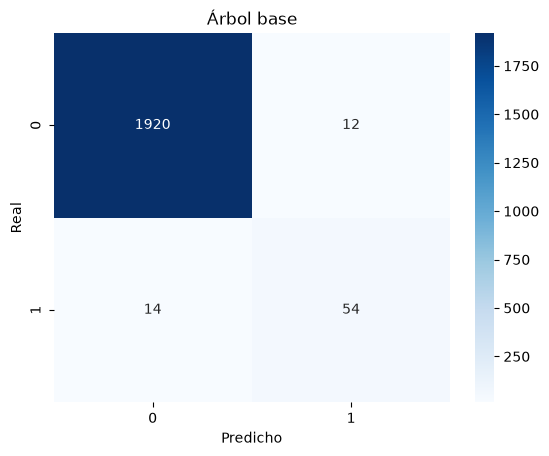

Mejores parámetros: {'criterion': 'gini', 'max_depth': 5, 'min_samples_leaf': 1, 'min_samples_split': 20} | CV score: 0.8918862090290662
== Árbol GridSearch == acc=0.9925 | F1(falla)=0.882 | recall=0.824 | ROC-AUC=0.942 | costo=123
              precision    recall  f1-score   support

           0       0.99      1.00      1.00      1932
           1       0.95      0.82      0.88        68

    accuracy                           0.99      2000
   macro avg       0.97      0.91      0.94      2000
weighted avg       0.99      0.99      0.99      2000



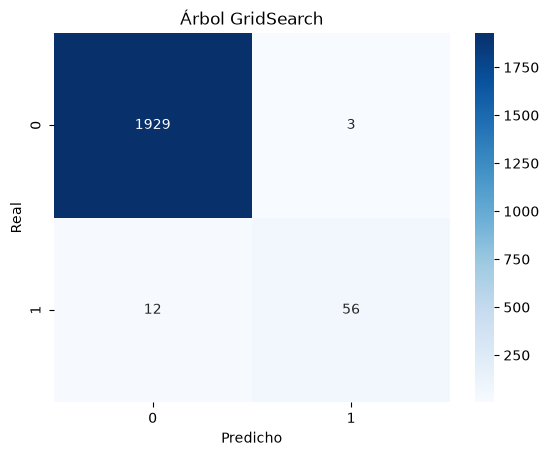

Mejores parámetros: {'criterion': 'entropy', 'max_depth': 6, 'min_samples_leaf': 4, 'min_samples_split': 9} | CV score: 0.8853908108698025
== Árbol RandomSearch == acc=0.9920 | F1(falla)=0.873 | recall=0.809 | ROC-AUC=0.927 | costo=133
              precision    recall  f1-score   support

           0       0.99      1.00      1.00      1932
           1       0.95      0.81      0.87        68

    accuracy                           0.99      2000
   macro avg       0.97      0.90      0.93      2000
weighted avg       0.99      0.99      0.99      2000



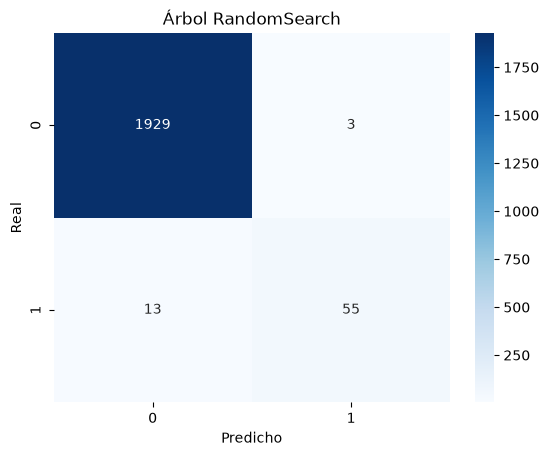

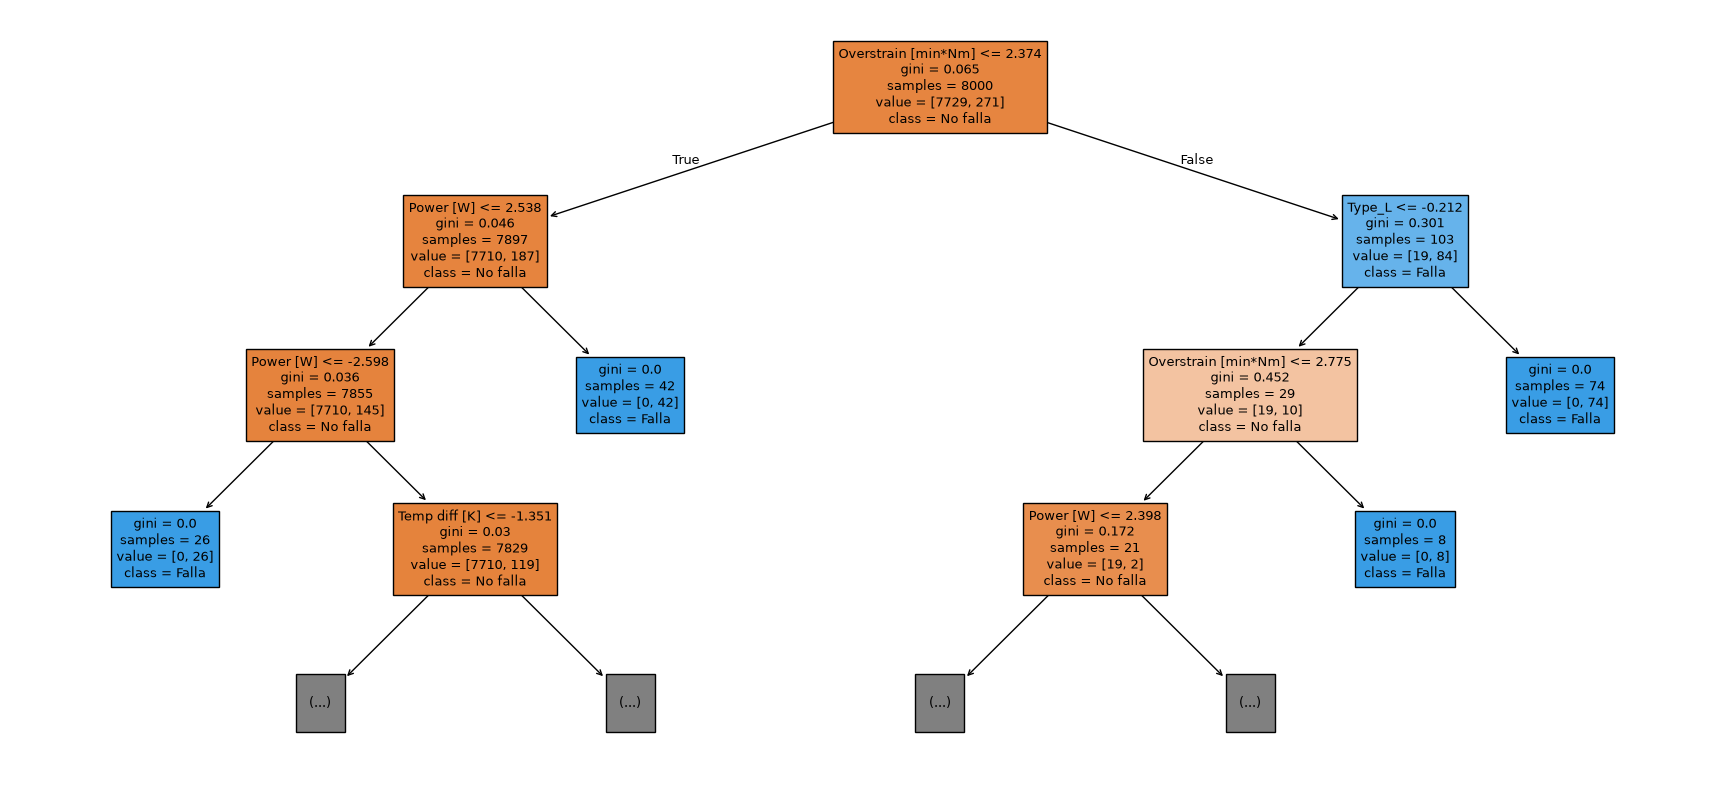

In [38]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
from scipy.stats import randint

# Base
dt = DecisionTreeClassifier(random_state=RANDOM_STATE)
dt.fit(X_train_s, y_train)
evaluar_modelos_clasificacion("Árbol base", dt)

# GridSearchCV
param_grid = {
    "max_depth": [3, 5, 7, 10, None],
    "min_samples_split": [2, 10, 20],
    "min_samples_leaf": [1, 5, 10],
    "criterion": ["gini", "entropy"],
}
gs_dt = GridSearchCV(DecisionTreeClassifier(random_state=RANDOM_STATE),
                     param_grid, cv=5, scoring=SCORING, n_jobs=-1)
gs_dt.fit(X_train_s, y_train)
print("Mejores parámetros:", gs_dt.best_params_, "| CV score:", gs_dt.best_score_)
evaluar_modelos_clasificacion("Árbol GridSearch", gs_dt.best_estimator_)

# RandomizedSearchCV
param_dist = {
    "max_depth": randint(2, 15),
    "min_samples_split": randint(2, 30),
    "min_samples_leaf": randint(1, 20),
    "criterion": ["gini", "entropy"],
}
rs_dt = RandomizedSearchCV(DecisionTreeClassifier(random_state=RANDOM_STATE),
                           param_dist, n_iter=20, cv=5, scoring=SCORING,
                           random_state=RANDOM_STATE, n_jobs=-1)
rs_dt.fit(X_train_s, y_train)
print("Mejores parámetros:", rs_dt.best_params_, "| CV score:", rs_dt.best_score_)
evaluar_modelos_clasificacion("Árbol RandomSearch", rs_dt.best_estimator_)

# Visualizar el mejor árbol
mejor_arbol = gs_dt.best_estimator_
plt.figure(figsize=(22, 10))
plot_tree(mejor_arbol, feature_names=X.columns, class_names=["No falla", "Falla"],
          filled=True, max_depth=3, fontsize=9)
plt.show()

### Modelos adicionales: Random Forest, kNN y Regresión Logística balanceada
Se agregan modelos no lineales (H4) y una versión balanceada de la regresión logística (`class_weight="balanced"`) para atacar el desbalance de clases.

Mejores parámetros RF: {'class_weight': None, 'max_depth': None, 'min_samples_leaf': 3, 'n_estimators': 300} | CV F1: 0.8792
== Random Forest GridSearch == acc=0.9915 | F1(falla)=0.864 | recall=0.794 | ROC-AUC=0.978 | costo=143
              precision    recall  f1-score   support

           0       0.99      1.00      1.00      1932
           1       0.95      0.79      0.86        68

    accuracy                           0.99      2000
   macro avg       0.97      0.90      0.93      2000
weighted avg       0.99      0.99      0.99      2000



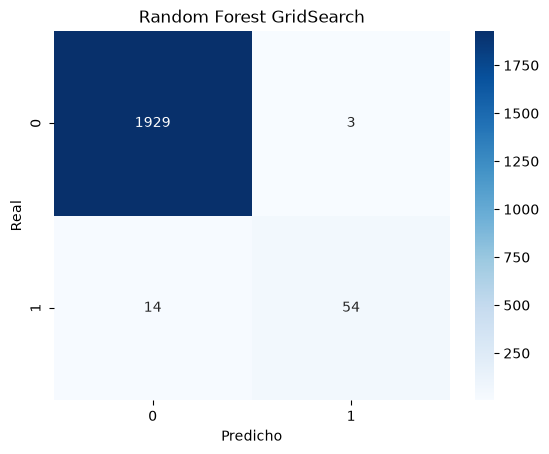

Mejores parámetros kNN: {'n_neighbors': 5, 'weights': 'distance'} | CV F1: 0.4788
== kNN GridSearch == acc=0.9755 | F1(falla)=0.473 | recall=0.324 | ROC-AUC=0.869 | costo=463
              precision    recall  f1-score   support

           0       0.98      1.00      0.99      1932
           1       0.88      0.32      0.47        68

    accuracy                           0.98      2000
   macro avg       0.93      0.66      0.73      2000
weighted avg       0.97      0.98      0.97      2000



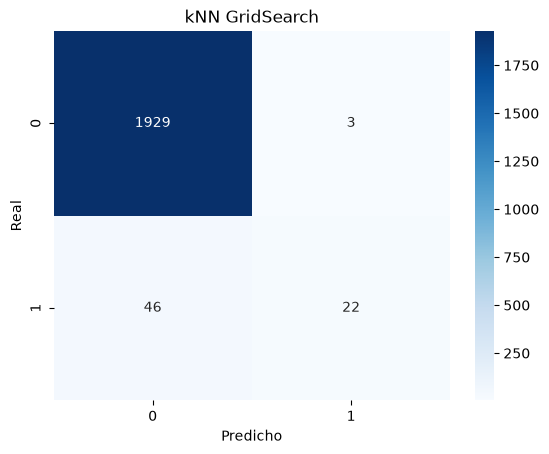

== RegLogistica balanceada == acc=0.8590 | F1(falla)=0.299 | recall=0.882 | ROC-AUC=0.938 | costo=354
              precision    recall  f1-score   support

           0       1.00      0.86      0.92      1932
           1       0.18      0.88      0.30        68

    accuracy                           0.86      2000
   macro avg       0.59      0.87      0.61      2000
weighted avg       0.97      0.86      0.90      2000



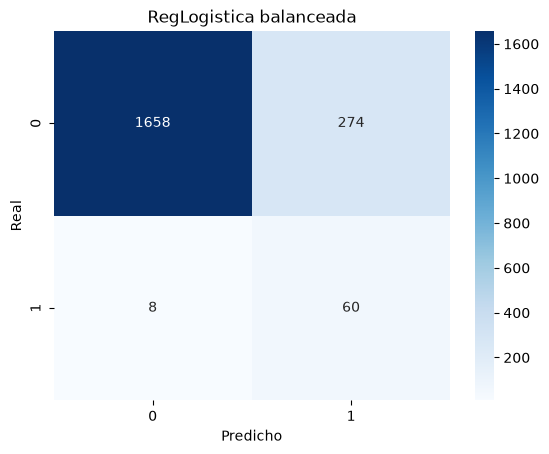

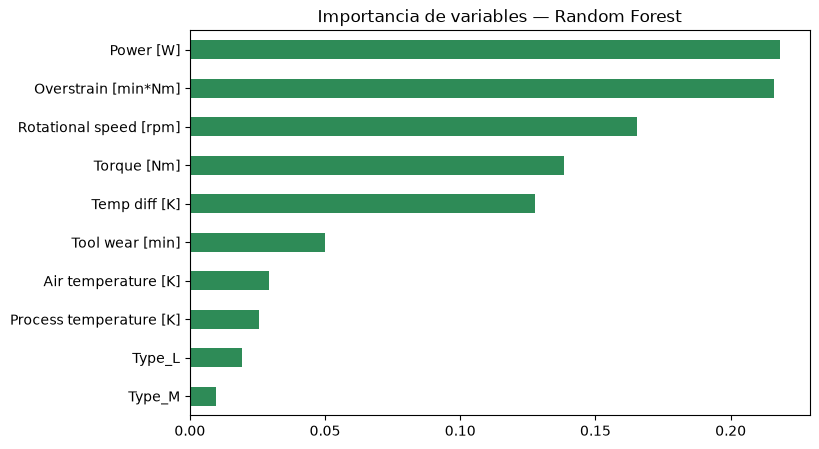

In [39]:
from sklearn.ensemble import RandomForestClassifier

# Random Forest
rf_grid = {"n_estimators": [300], "max_depth": [None, 10, 20], "min_samples_leaf": [1, 3],
           "class_weight": [None, "balanced_subsample"]}
gs_rf = GridSearchCV(RandomForestClassifier(random_state=RANDOM_STATE), rf_grid, cv=5, scoring=SCORING, n_jobs=-1)
gs_rf.fit(X_train_s, y_train)
print("Mejores parámetros RF:", gs_rf.best_params_, "| CV F1:", round(gs_rf.best_score_, 4))
evaluar_modelos_clasificacion("Random Forest GridSearch", gs_rf.best_estimator_)

# kNN
gs_knn = GridSearchCV(KNeighborsClassifier(), {"n_neighbors": [3, 5, 7, 11, 15], "weights": ["uniform", "distance"]},
                      cv=5, scoring=SCORING, n_jobs=-1)
gs_knn.fit(X_train_s, y_train)
print("Mejores parámetros kNN:", gs_knn.best_params_, "| CV F1:", round(gs_knn.best_score_, 4))
evaluar_modelos_clasificacion("kNN GridSearch", gs_knn.best_estimator_)

# Regresión logística balanceada
lr_bal = LogisticRegression(class_weight="balanced", random_state=RANDOM_STATE, max_iter=1000).fit(X_train_s, y_train)
evaluar_modelos_clasificacion("RegLogistica balanceada", lr_bal)

# Importancia de variables (H1)
imp = pd.Series(gs_rf.best_estimator_.feature_importances_, index=X.columns).sort_values()
imp.plot.barh(figsize=(8, 5), color="seagreen"); plt.title("Importancia de variables — Random Forest"); plt.show()

**Interpretación:**
* **Random Forest** logra F1 = 0.864, recall = 0.794 y **ROC-AUC = 0.978**, el mejor ranking de riesgo de todos los modelos.
* **kNN** (F1 0.47) apenas supera a los modelos lineales.
* La **Regresión Logística balanceada** detecta el 88 % de las fallas, pero con 274 falsas alarmas (precisión 0.18): muestra el costo de forzar el recall en un modelo lineal.

**Importancia de variables (H1 se confirma):** las variables más importantes son **Power (0.22)**, **Overstrain (0.22)**, rpm (0.17), torque (0.14) y Temp diff (0.13). Las temperaturas solas (~0.03) y `Type` (~0.02) casi no aportan. Las **3 variables derivadas del ETL están entre las 5 primeras**: crear KPIs con sentido físico mejoró los modelos (el árbol del notebook original tenía F1 0.73; con las variables derivadas y optimizando F1 llega a 0.88).

### Validación de robustez (validación cruzada estratificada 5-fold sobre train)
Una sola partición train/test con 68 fallas en test puede dar resultados por azar. Se repite la evaluación en 5 particiones y se reporta media ± desviación.

In [40]:
from sklearn.model_selection import StratifiedKFold, cross_validate

cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
candidatos = {
    "Random Forest GridSearch": gs_rf.best_estimator_,
    "Árbol GridSearch": gs_dt.best_estimator_,
    "kNN GridSearch": gs_knn.best_estimator_,
    "LDA GridSearch": gs_lda.best_estimator_,
    "RegLogistica balanceada": lr_bal,
    "NaiveBayes base": GaussianNB(),
}
filas = []
for nombre, m in candidatos.items():
    s = cross_validate(clone(m), X_train_s, y_train, cv=cv5, n_jobs=-1,
                       scoring=["f1", "recall", "precision", "roc_auc"])
    filas.append({"modelo": nombre, **{f"{k} (media±std)": f"{s['test_' + k].mean():.3f} ± {s['test_' + k].std():.3f}"
                                       for k in ["f1", "recall", "precision", "roc_auc"]}})
display(pd.DataFrame(filas).set_index("modelo"))

,f1 (media±std),recall (media±std),precision (media±std),roc_auc (media±std)
modelo,,,,
Random Forest GridSearch,0.875 ± 0.024,0.804 ± 0.038,0.961 ± 0.030,0.979 ± 0.014
Árbol GridSearch,0.888 ± 0.015,0.834 ± 0.027,0.950 ± 0.014,0.975 ± 0.020
kNN GridSearch,0.478 ± 0.057,0.347 ± 0.046,0.769 ± 0.077,0.864 ± 0.018
LDA GridSearch,0.448 ± 0.064,0.406 ± 0.064,0.500 ± 0.062,0.890 ± 0.020
RegLogistica balanceada,0.271 ± 0.011,0.841 ± 0.046,0.162 ± 0.008,0.923 ± 0.013
NaiveBayes base,0.491 ± 0.032,0.550 ± 0.036,0.445 ± 0.036,0.919 ± 0.017


**Interpretación:** los modelos de árbol son **estables**:
* **Árbol:** F1 = 0.888 ± 0.015.
* **Random Forest:** F1 = 0.875 ± 0.024, con ROC-AUC = 0.979 ± 0.014.

Su desviación es baja comparada con la distancia que los separa del resto (≤ 0.49 de F1). Por eso la ventaja frente a los modelos lineales **no depende de la partición train/test**. Entre árbol y Random Forest la diferencia de F1 (0.013) es menor que su desviación estándar: en F1 están **empatados**.

### Ajuste del umbral de decisión según el costo del error
Por defecto los modelos marcan falla si la probabilidad ≥ 0.5. En mantenimiento conviene un umbral menor si el costo de no detectar una falla es mayor. El umbral se elige con predicciones *out-of-fold* sobre **train** (no se toca el test) y luego se evalúa en test.

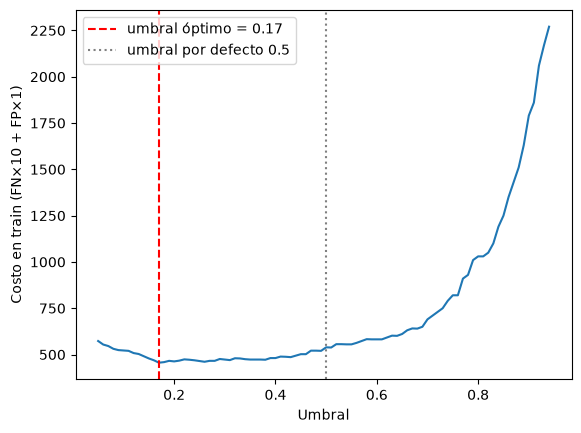

== Random Forest umbral 0.17 == acc=0.9850 | F1(falla)=0.795 | recall=0.853 | ROC-AUC=0.978 | costo=120
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      1932
           1       0.74      0.85      0.79        68

    accuracy                           0.98      2000
   macro avg       0.87      0.92      0.89      2000
weighted avg       0.99      0.98      0.99      2000



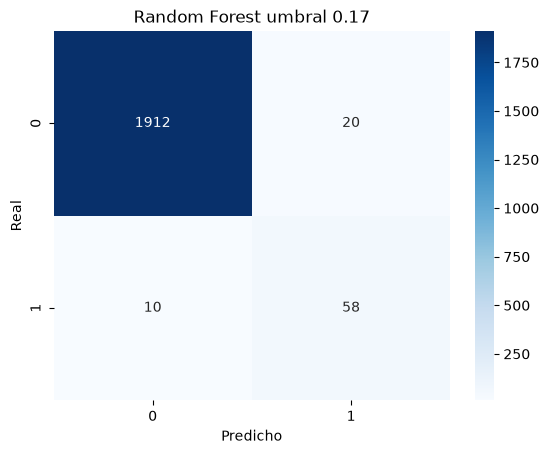

In [41]:
from sklearn.model_selection import cross_val_predict

mejor_modelo = gs_rf.best_estimator_
proba_oof = cross_val_predict(clone(mejor_modelo), X_train_s, y_train, cv=cv5, method="predict_proba", n_jobs=-1)[:, 1]
umbrales = np.arange(0.05, 0.95, 0.01)
costos = []
for u in umbrales:
    tn, fp, fn, tp = confusion_matrix(y_train, (proba_oof >= u).astype(int)).ravel()
    costos.append(COSTO_FN * fn + COSTO_FP * fp)
umbral_opt = float(umbrales[int(np.argmin(costos))])

plt.plot(umbrales, costos); plt.axvline(umbral_opt, color="red", ls="--", label=f"umbral óptimo = {umbral_opt:.2f}")
plt.axvline(0.5, color="gray", ls=":", label="umbral por defecto 0.5")
plt.xlabel("Umbral"); plt.ylabel(f"Costo en train (FN×{COSTO_FN} + FP×{COSTO_FP})"); plt.legend(); plt.show()

evaluar_modelos_clasificacion(f"Random Forest umbral {umbral_opt:.2f}", mejor_modelo, umbral=umbral_opt)

**Interpretación:** con el supuesto de que un FN cuesta 10 veces un FP, el umbral óptimo en train es **0.17**, no 0.5. En test, el Random Forest con umbral 0.17 cambia así:
* Fallas no detectadas: de 14 a **10**.
* Recall: de 0.794 a **0.853**.
* Falsas alarmas: de 3 a 20.
* Costo total: de 143 a **120** (−16 %).

En planta esto significa aceptar unas pocas inspecciones preventivas de más a cambio de evitar paradas no planificadas. Si la relación de costos real es otra, basta con cambiar `COSTO_FN` y `COSTO_FP` y volver a ejecutar.

### Comparación final de modelos (test)

,accuracy,precision,recall,f1,roc_auc,FN,FP,costo
Random Forest umbral 0.17,0.985,0.744,0.853,0.795,0.978,10.0,20.0,120.0
Árbol GridSearch,0.992,0.949,0.824,0.882,0.942,12.0,3.0,123.0
Árbol RandomSearch,0.992,0.948,0.809,0.873,0.927,13.0,3.0,133.0
Random Forest GridSearch,0.992,0.947,0.794,0.864,0.978,14.0,3.0,143.0
Árbol base,0.987,0.818,0.794,0.806,0.894,14.0,12.0,152.0
RegLogistica balanceada,0.859,0.180,0.882,0.299,0.938,8.0,274.0,354.0
NaiveBayes base,0.962,0.440,0.485,0.462,0.926,35.0,42.0,392.0
NaiveBayes GridSearch,0.962,0.440,0.485,0.462,0.926,35.0,42.0,392.0
NaiveBayes RandomSearch,0.962,0.440,0.485,0.462,0.926,35.0,42.0,392.0
NaiveBayes sin PCA,0.962,0.440,0.485,0.462,0.926,35.0,42.0,392.0


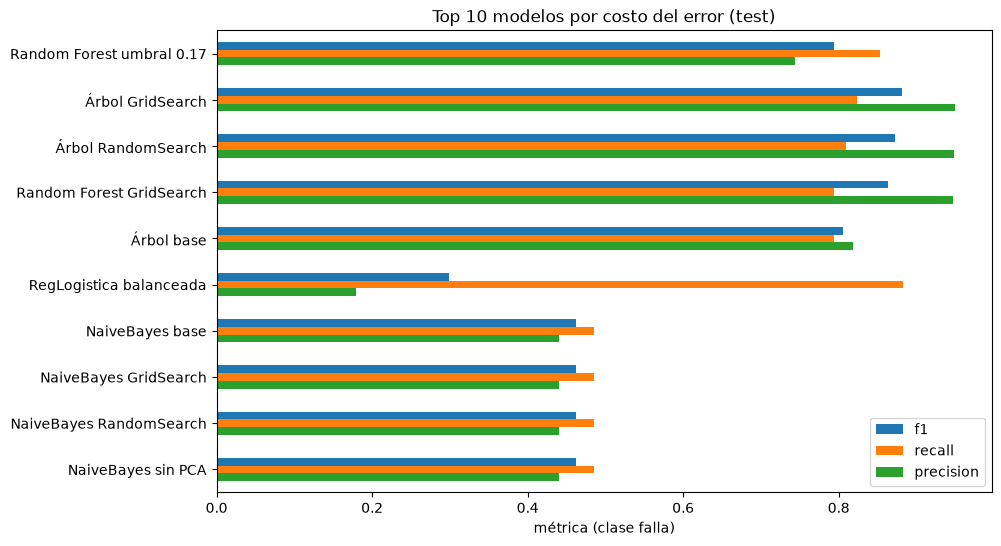

In [42]:
tabla_final = pd.DataFrame(resultados).T[["accuracy", "precision", "recall", "f1", "roc_auc", "FN", "FP", "costo"]]
tabla_final = tabla_final.astype(float).sort_values(["costo", "f1"], ascending=[True, False])
display(tabla_final.round(3))

top = tabla_final.head(10)
top[["f1", "recall", "precision"]].plot.barh(figsize=(10, 6)).invert_yaxis()
plt.title("Top 10 modelos por costo del error (test)"); plt.xlabel("métrica (clase falla)"); plt.show()

### Justificación de la elección final

**Modelo elegido: Random Forest (GridSearch) con umbral de decisión 0.17.**

| Criterio | Random Forest umbral 0.17 | Árbol GridSearch | Mejor modelo lineal (RegLog balanceada) |
|---|---|---|---|
| Costo del error (test) | **120** | 123 | 354 |
| Fallas no detectadas (FN) | **10 de 68** | 12 | 8 |
| Falsas alarmas (FP) | 20 | **3** | 274 |
| Recall falla | **0.853** | 0.824 | 0.882 |
| F1 falla | 0.795 | **0.882** | 0.299 |
| ROC-AUC | **0.978** | 0.942 | 0.938 |
| F1 CV 5-fold | 0.875 ± 0.024 | **0.888 ± 0.015** | 0.271 ± 0.011 |

* Tiene el **menor costo industrial** y deja escapar menos fallas que cualquier modelo con precisión aceptable.
* Tiene el **mayor ROC-AUC**, es decir, ordena mejor las máquinas por riesgo. Eso sirve para priorizar inspecciones aunque cambie el umbral.
* **Alternativa:** si la planta prioriza la **interpretabilidad** (reglas explicables para operarios), el **Árbol de decisión (profundidad 5)** es casi equivalente en costo (123 vs 120), tiene el mejor F1 y genera muchas menos falsas alarmas.

### Respuesta a las hipótesis
| Hipótesis | Resultado |
|---|---|
| H1 — torque, desgaste y potencia dominan | ✅ Confirmada: Power, Overstrain, rpm y torque son las variables más importantes; las temperaturas solas aportan poco (aunque Temp diff sí pesa). |
| H2 — hay regímenes con riesgo distinto | ✅ Confirmada: el régimen "cálido + herramienta gastada" tiene 6.2 % de fallas frente a 1.8 % del régimen "frío". |
| H3 — PCA reduce sin perder capacidad predictiva | ❌ Rechazada: reducir a 5 componentes baja el F1 en todos los modelos. |
| H4 — los árboles superan a los modelos lineales | ✅ Confirmada: F1 ≈ 0.88 frente a ≤ 0.46. |
| H5 — accuracy no sirve para elegir | ✅ Confirmada: la RegLog con PCA tiene 96.6 % de accuracy y detecta **0** fallas. |

### Limitaciones
* El dataset es **sintético**: hay que validar el modelo con datos reales de la planta antes de usarlo.
* La relación de costos FN:FP = 10:1 es un **supuesto**. Debe reemplazarse por los costos reales de parada e inspección.
* Solo hay 68 fallas en test; el intervalo de confianza de las métricas es amplio (ver la validación cruzada).
* Las fallas aleatorias (RNF) no son predecibles por diseño.